In [1]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


# abs_path = str(pathlib.Path(hostname).parent.absolute())
abs_path = str(pathlib.Path(hostname).parent.absolute())

WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname or "pingo" in hostname or "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/ANX_obs_daily/final/"


INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory to put in reflectivity processed data
try:
    new_dir = pathlib.Path(FIG_DIR)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

nc_dir = os.path.join(OUTPUT_DATA_DIR, 'ANX_obs')


ivan.uio.no


In [2]:
# supress warnings
import warnings
warnings.filterwarnings('ignore')

# import packages
from imports import(glob, pd, IMProToo, xr, np, fnmatch, pearsonr, plt, cm, LinearSegmentedColormap, set_context, Rectangle, Patch, DateFormatter, Line2D)
import functions as fct

In [3]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

In [4]:
# reload imports
%load_ext autoreload
%autoreload 2

In [5]:
# plot cosmetics
set_context('paper', rc={"lines.linewidth": 2}, font_scale=1.5, )

In [6]:
version = IMProToo.__version__

In [7]:
site = "ANX"
year = "2023"

base_height = np.arange(100,3200, 100) # Predefined MRR profile

# define the prefactor "a" and exponent "b" in Z=a*S^b
# a = 60
# b = 1.

In [8]:
file_pattern = f"{INPUT_DATA_DIR}/MRR_ANX/maahn/mrr_improtoo_{version}_{site}_*2023*.nc"
file_list = sorted(glob(file_pattern))


In [9]:
# filename = f"Z_S_2Tm_WD_WS_class_precip_event_dt_offset_{site}_{year}.nc"


In [10]:
# for a in np.arange(50,80,5):#305,5):
#     for b in np.arange(1.8,3.05,0.05):#3.05,0.05):
#         a = int(a)
#         b = b.round(2)
#         nc_dir = os.path.join(OUTPUT_DATA_DIR, f'ANX_obs_EM_{a}_{b}')
#         out_name = os.path.join(nc_dir, filename)
        
#         if out_name not in glob(out_name):
#             create_final_file(INPUT_DATA_DIR, OUTPUT_DATA_DIR, a, b.round(2), site, year, version, base_height)

In [11]:
# List all files
file_paths = sorted(glob(os.path.join(OUTPUT_DATA_DIR, f'ANX_obs_EM_*', f'Z_S_2Tm_WD_WS_class_precip_event_dt_offset_{site}_{year}.nc')))
# open all datasets individually first
datasets = [xr.open_dataset(file_path) for file_path in file_paths]
# combine them 
combined_dataset = xr.combine_by_coords(datasets, compat='override')

In [12]:
vars_to_keep = ["Geonor", "air_temperature", "wind_direction", "wind_speed", "snowflake_class_name", "rate_mm_h", "start_time", "delta_h"]

In [13]:
pattern = "*_400_mm_h"
# filter variables based on pattern
filtered_vars = [v for v in combined_dataset if fnmatch.fnmatch(v, pattern)]
vars_to_keep = vars_to_keep+filtered_vars
# select only chosen variables
ds_subset = combined_dataset[vars_to_keep]

In [14]:
df_event_offset = ds_subset.to_dataframe()

##### Filter the dominant snowflake class and create individual dataframes

In [15]:

sf_class_dict = {}
# for dt in ['event_offset', ]:#'1min', '5min', '10min', '30min', '60min']:
aggregate   = df_event_offset[df_event_offset['snowflake_class_name'] == 'aggregate']
graupel     = df_event_offset[df_event_offset['snowflake_class_name'] == 'graupel']
mixed       = df_event_offset[df_event_offset['snowflake_class_name'] == 'mixed']
pristine    = df_event_offset[df_event_offset['snowflake_class_name'] == 'pristine']

sf_class_dict = {'aggregate':aggregate, 'graupel':graupel, 'mixed':mixed, 'pristine':pristine, 'all': df_event_offset}

In [16]:
heavy_precip = dict()
low_precip = dict()
for class_key in sf_class_dict.keys():
    heavy_precip[class_key] =  sf_class_dict[class_key].loc[sf_class_dict[class_key]['rate_mm_h'] >= 6., :]
    low_precip[class_key] = sf_class_dict[class_key].loc[sf_class_dict[class_key]['rate_mm_h'] < 6., :]

In [17]:
# convert wind into [0, 360)
df_event_offset['wind_direction'] = df_event_offset['wind_direction'] % 360

df_event_offset['wind_direction_sector'] = pd.cut(df_event_offset['wind_direction'], bins=[0., 45., 135., 225., 315., 360.], labels = ['N', 'E', 'S',  'W', 'N'], include_lowest=True, right=False, ordered=False)

wd_sector_dict = {}
northerly = df_event_offset[df_event_offset['wind_direction_sector'] == 'N']
easterly = df_event_offset[df_event_offset['wind_direction_sector'] == 'E']
southerly = df_event_offset[df_event_offset['wind_direction_sector'] == 'S']
westerly = df_event_offset[df_event_offset['wind_direction_sector'] == 'W']

wd_sector_dict = {'North': northerly, 'East': easterly, 'South': southerly, 'West': westerly}

for class_key in wd_sector_dict.keys():
    heavy_precip[class_key] = wd_sector_dict[class_key].loc[wd_sector_dict[class_key]['rate_mm_h'] >= 6.,:]
    low_precip[class_key] = wd_sector_dict[class_key].loc[wd_sector_dict[class_key]['rate_mm_h'] <6., :]

In [18]:
# a_range = np.arange(50,305,5)
# b_range = np.arange(1,3.05,0.05)

a_range = np.arange(10,330,10)
b_range = np.arange(0.8,5.1,0.1)
# 



In [19]:
df_rmse = dict()
df_mae = dict()
counts = dict()
for limits, dicts in zip(['snowflake_class', 'wind_direction_sector', 'high_precipitation', 'low_precipitation'], [sf_class_dict, wd_sector_dict, heavy_precip, low_precip]):
    df_rmse[limits] = dict()
    df_mae[limits] = dict()
    counts[limits] = dict()
    for class_key in dicts.keys():
        df_rmse[limits][class_key] = pd.DataFrame(index = a_range.astype(int), columns=b_range.round(2))
        df_mae[limits][class_key] = pd.DataFrame(index = a_range.astype(int), columns=b_range.round(2))
        for a in a_range:
            for b in b_range:
                a = int(a)
                b = b.round(2)
                if f"S_{a}_{b}_400_mm_h" in dicts[class_key].columns:
                    xval = dicts[class_key]["rate_mm_h"]
                    yval = dicts[class_key][f"S_{a}_{b}_400_mm_h"]
                else:
                    continue
                mask = (
                    (xval > 0) & 
                    (yval > 0) &
                    np.isfinite(xval) &
                    np.isfinite(yval))
                xval = xval[mask]
                yval = yval[mask]

                counts[limits][class_key] = len(xval)

                # Transform the data to logarithmic scales
                log_x = np.log10(xval)
                log_y = np.log10(yval)

                # # compute error between logS_ret and logS_obs
                # compute error to the 1:1 line
                err = log_y - log_x # err = log(S_ret/S_obs)   
                                    # err == 0 perfect retrieval 
                                    # err == +0.3 retrieved SWE is 2x too large
                                    # err == -0.3 retrieved SWE is 2x too small
                                    # err == 1 retrieved SWE is 10x too large
                rmse = np.sqrt(np.nanmean(err**2))  # minimizing RMSE: penalizes large multiplicative outliers strongly,
                                                    # strongly influenced by rare but severe mis-retrievals
                                                    # best if caring about worst-case performance
                                                    # Which Z-S minimizes large relative errors?
                df_rmse[limits][class_key].at[a,b] = rmse
                mae = np.nanmean(np.abs(err))       # minimizing MAE: typical (median-like) multiplicative error
                                                    # robust to outliers
                                                    # best if caring about overall typcial behaviour
                                                    # Which Z-S gives the most consistently correct SWE?
                df_mae[limits][class_key].at[a,b] = mae


        

        df_rmse[limits][class_key] = df_rmse[limits][class_key].sort_index(axis=1)
        df_rmse[limits][class_key] = df_rmse[limits][class_key].astype(float)

        df_mae[limits][class_key] = df_mae[limits][class_key].sort_index(axis=1)
        df_mae[limits][class_key] = df_mae[limits][class_key].astype(float)
                    

In [20]:
cmap = cm.managua  # define the colormap
# extract all colors from the colormap
cmaplist = [cmap(i) for i in range(cmap.N)]
# create the new map
custom_cmap = LinearSegmentedColormap.from_list(
'Custom cmap', cmaplist, 10)

In [21]:
custom_colors = {  
                     'aggregate': LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(1),  
                     'graupel':LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(4),   
                     'mixed': LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(2),
                     'all': LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(5),
}

In [22]:
def edges_from_centers(centers):
    centers = np.asarray(centers)
    d = np.diff(centers)
    edges = np.empty(len(centers) + 1)
    edges[1:-1] = centers[:-1] + d / 2
    edges[0] = centers[0] - d[0] / 2
    edges[-1] = centers[-1] + d[-1] / 2
    return edges

In [23]:
def find_bin(val, edges):
    return np.searchsorted(edges, val) -1 

In [24]:
def draw_lit_box(ax, box, a_edges, b_edges, lw=2.5):
    ia = find_bin(box["a"], a_edges)
    ib = find_bin(box["b"], b_edges)

    x0 = b_edges[ib]
    y0 = a_edges[ia]
    width  = b_edges[ib + 1] - b_edges[ib]
    height = a_edges[ia + 1] - a_edges[ia]

    ax.add_patch(Rectangle(
        (x0, y0),
        width,
        height,
        fill=False,
        edgecolor=box["color"],
        linewidth=lw,
        zorder=11
    ))


In [25]:
LITERATURE_BOXES = {
    "A": dict(a=56,    b=1.20, color="lime",    label="Matrosov (2007)"),
    "B": dict(a=134,   b=1.25, color="yellow",  label="Bracci et al. (2022)"),
    "C": dict(a=252,   b=2.03, color="magenta", label="Pu et al. (2020)"),
    "D": dict(a=77.61, b=1.22, color="cyan",    label="Schoger et al. (2021)"),
}

LIT_PLACEMENT = {
    # Physical categories
    ("aggregate", "graupel", "mixed", "all"): {
        "aggregate": ["A", "B"],
        "graupel":   ["C"],
        "all":       ["D"],
    },

    # Wind-direction categories
    ("North", "East", "South", "West"): {
        "North": ["A", "B", "C", "D"],
        "East":  ["A", "B", "C", "D"],
        "South": ["A", "B", "C", "D"],
        "West":  ["A", "B", "C", "D"],
    },
}

def get_lit_placement(category):
    key = tuple(category)
    if key not in LIT_PLACEMENT:
        raise ValueError(f"No literature placement defined for category={category}")
    return LIT_PLACEMENT[key]


In [26]:
def plt_chessboard(df, counts, cbar_label, category):
  

    custom_colors = {  
                     category[0]: LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(1),  
                     category[1]:LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(4),   
                     category[2]: LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(2),
                     category[3]: LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(5),
}
    

    fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(12,12), sharex=True, sharey=True)
    axs = np.atleast_2d(axs)
    for (i, ax), class_key in zip(enumerate(axs.flatten()), category):
        a_vals = df[class_key].index.values
        b_vals = df[class_key].columns.values

        a_edges = edges_from_centers(a_vals)
        b_edges = edges_from_centers(b_vals)

        A, B = np.meshgrid(df[class_key].columns, df[class_key].index)
        c = ax.pcolormesh(A, B, df[class_key].values, vmin=0, vmax=1, 
                      cmap=custom_cmap,shading="auto", edgecolors=(0, 0, 0, 0.2), linewidth=0.005, alpha=0.9)
        
        # hightlight the cell with minimum RMSE/MAE
        # index of min
        # iy, ix = df[class_key].stack().idxmin()
        iy, ix= np.unravel_index(np.nanargmin(df[class_key].values), df[class_key].shape)
        # rectangle edges
        x0 = b_edges[ix]
        y0 = a_edges[iy]
        width = b_edges[ix + 1] - b_edges[ix]
        height = a_edges[iy +1] - a_edges[iy] 
        ax.add_patch(Rectangle((x0, y0), width, height,
                        fill=False, edgecolor="black", linewidth=3.5, zorder=9))
        ax.add_patch(Rectangle((x0, y0), width, height,
                        fill=False, edgecolor="white", linewidth=2.5, zorder=10))

        # Highlight literature boxes
        placement = get_lit_placement(category)

        for study_key in placement.get(class_key, []):
            box = LITERATURE_BOXES[study_key]
            draw_lit_box(ax, box, a_edges, b_edges)


  


        # Ticks & labels
        ax.set_title(f"{class_key} (counts={counts[class_key]})".title(), fontweight='bold', color=custom_colors[class_key])
        ax.text(0.05, 0.95, fct.fig_label[i], fontweight="bold", horizontalalignment="center", verticalalignment='center', transform = ax.transAxes)

    for i in range(2):
        axs[i, 0].set_ylabel(r"$a$", fontsize=20)
        axs[1, i].set_xlabel(r"$b$", fontsize=20)
    
    lit_handles = [
    Patch(facecolor="none",
          edgecolor=box["color"],
          linewidth=2.5,
          label=box["label"])
    for box in LITERATURE_BOXES.values()
]


    fig.legend(
    handles=lit_handles,
    loc='upper left',
    bbox_to_anchor=(0.88, 0.28),  # tweak this
    frameon=True,
    title=r"Literature ($a$, $b$)"
)

    plt.tight_layout(rect=[0, 0, 0.9, 1])   # leave room for cbars
    cax = fig.add_axes([0.9, 0.3 , 0.015, 0.45]) # left, bottom, width, height
    cb = fig.colorbar(c, cax=cax, orientation='vertical', label=cbar_label,spacing="proportional", extend="both")


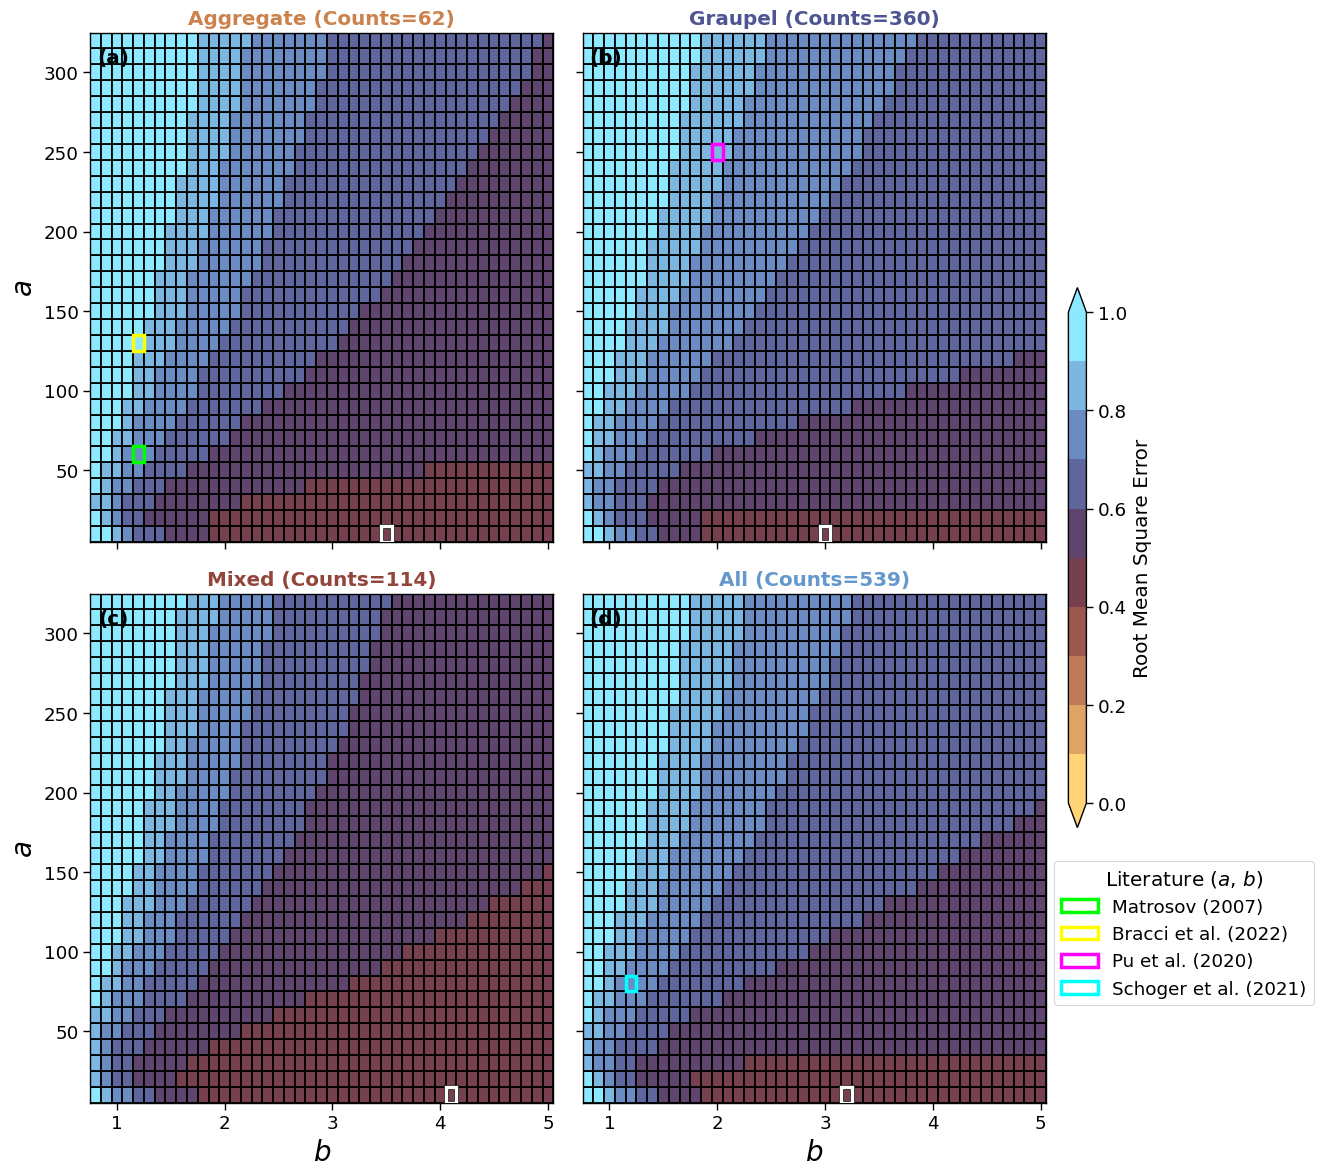

In [27]:
# snowflake classes no precipitation limits
plt_chessboard(df_rmse['snowflake_class'], counts['snowflake_class'], cbar_label="Root Mean Square Error", category=['aggregate', 'graupel', 'mixed', 'all'])

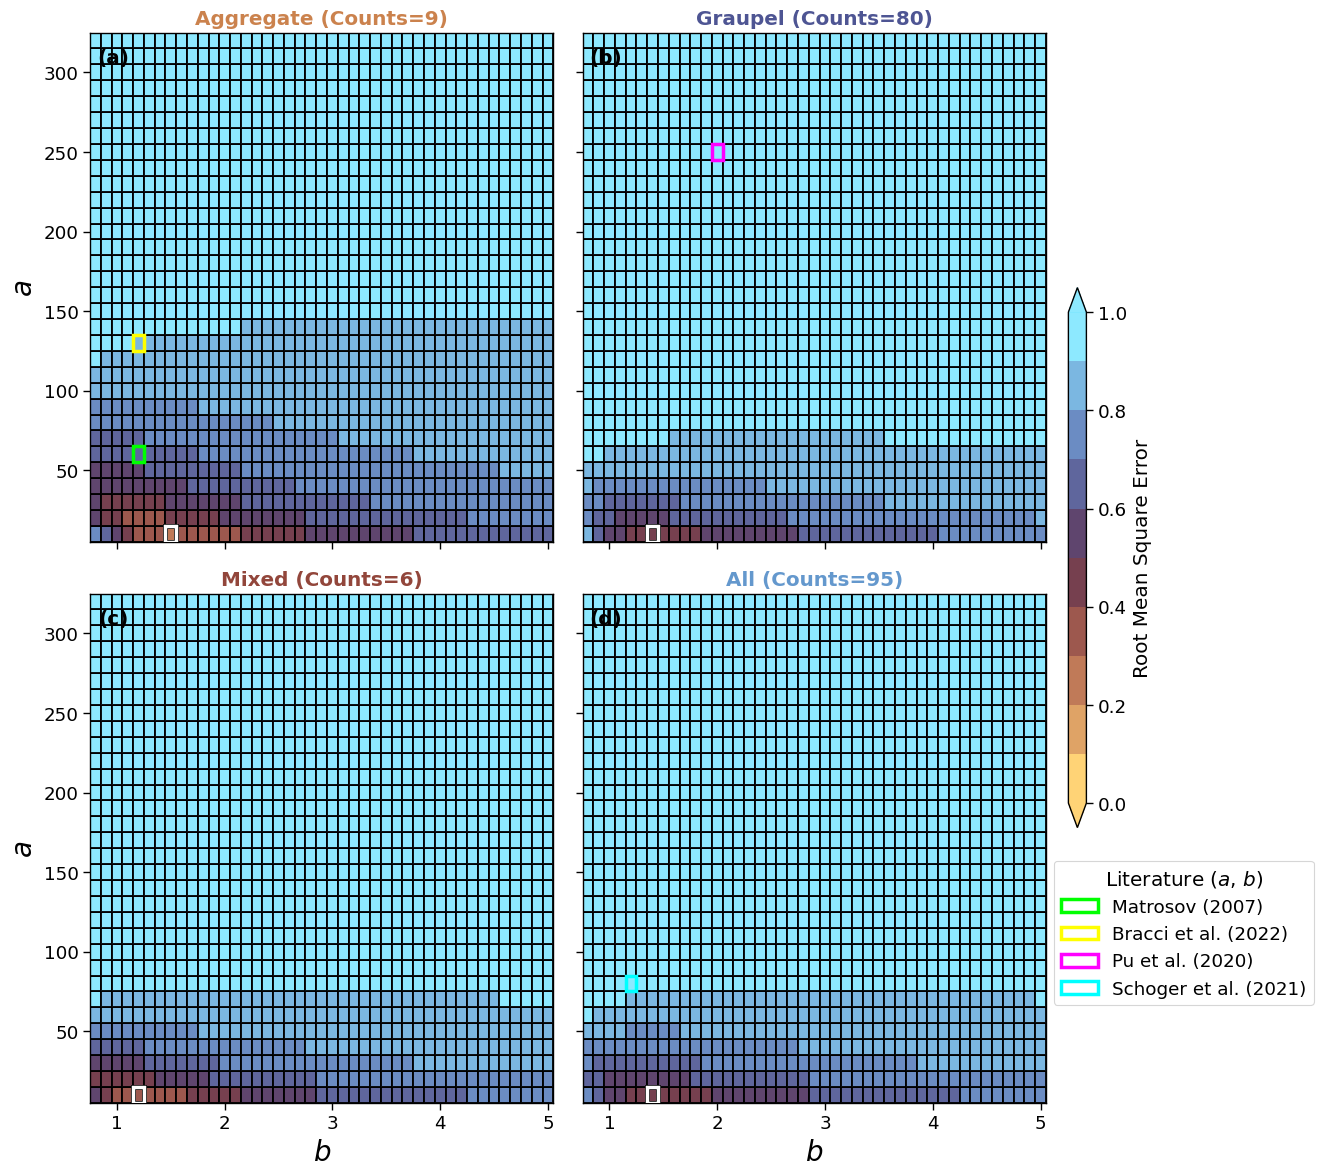

In [28]:
# snowflake classes high precipitation
plt_chessboard(df_rmse['high_precipitation'], counts['high_precipitation'], cbar_label="Root Mean Square Error", category=['aggregate', 'graupel', 'mixed', 'all'])

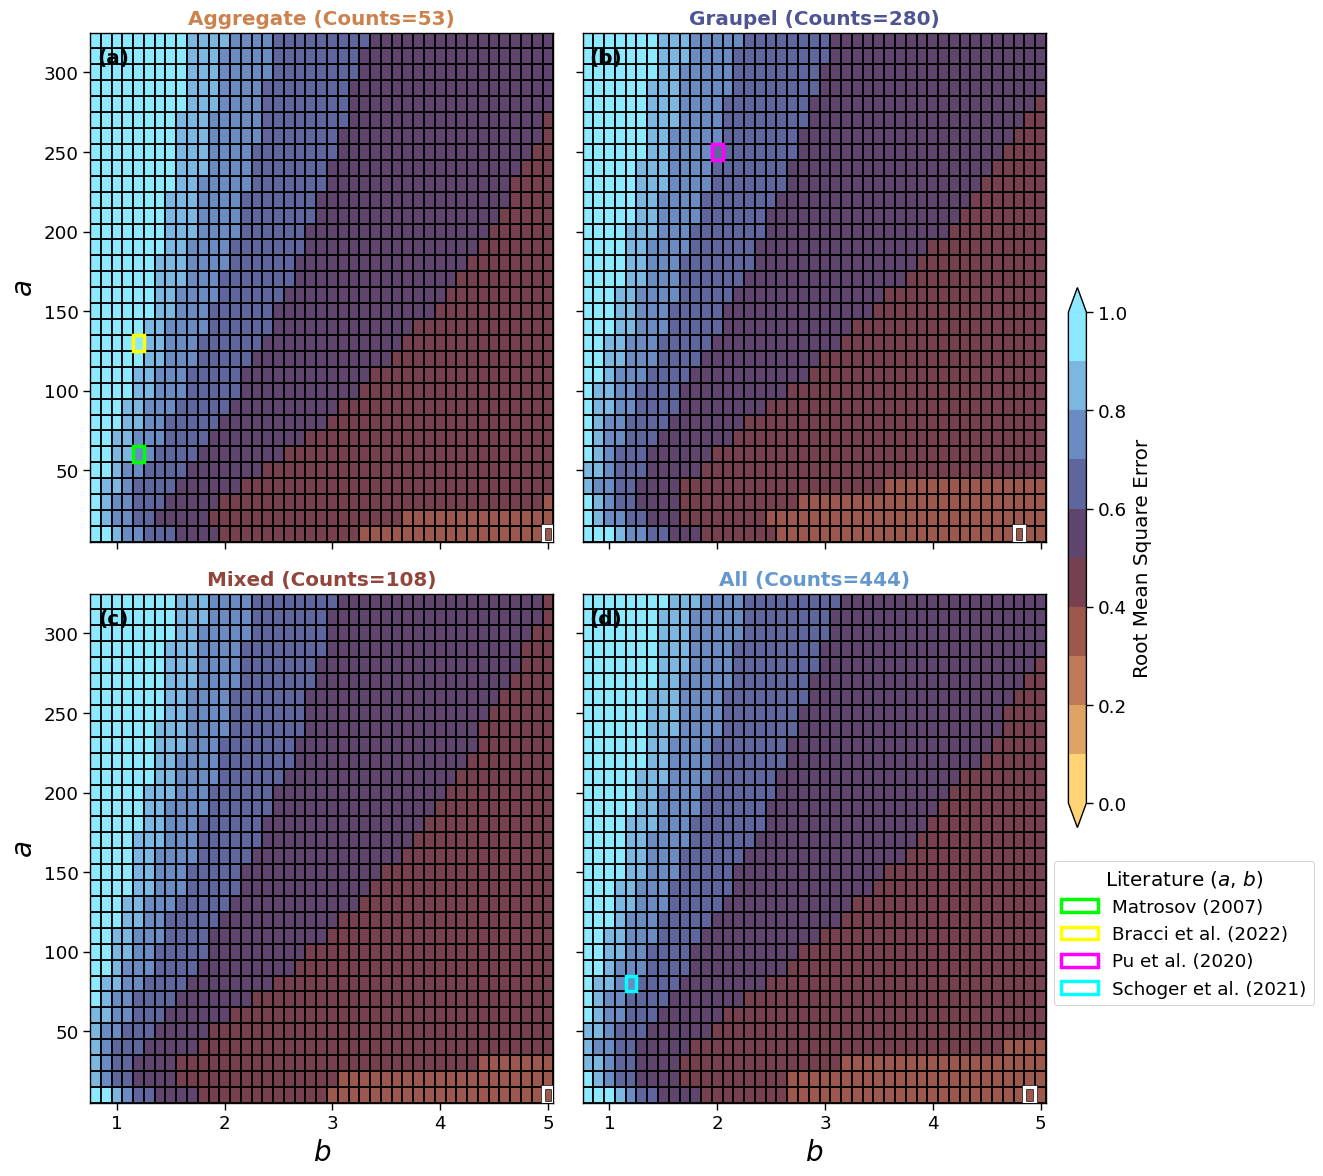

In [29]:
# snowflake classes low precipitation
plt_chessboard(df_rmse['low_precipitation'], counts['low_precipitation'], cbar_label="Root Mean Square Error", category=['aggregate', 'graupel', 'mixed', 'all'])

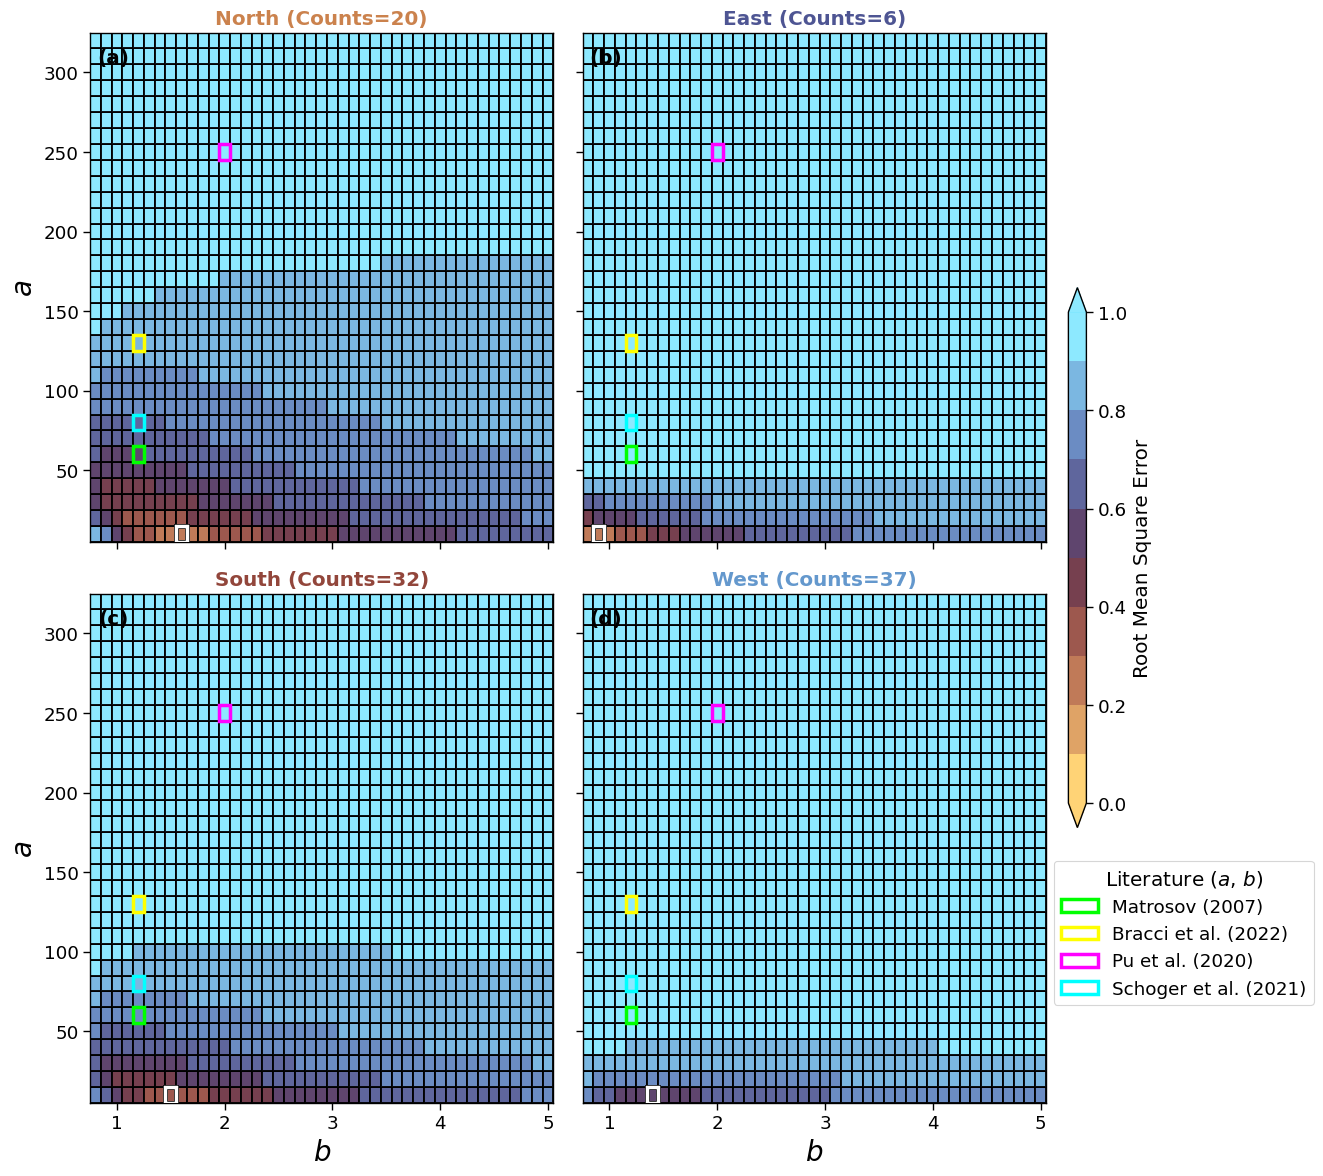

In [30]:
plt_chessboard(df_rmse['high_precipitation'], counts['high_precipitation'], cbar_label="Root Mean Square Error", category=['North', 'East', 'South', 'West'])

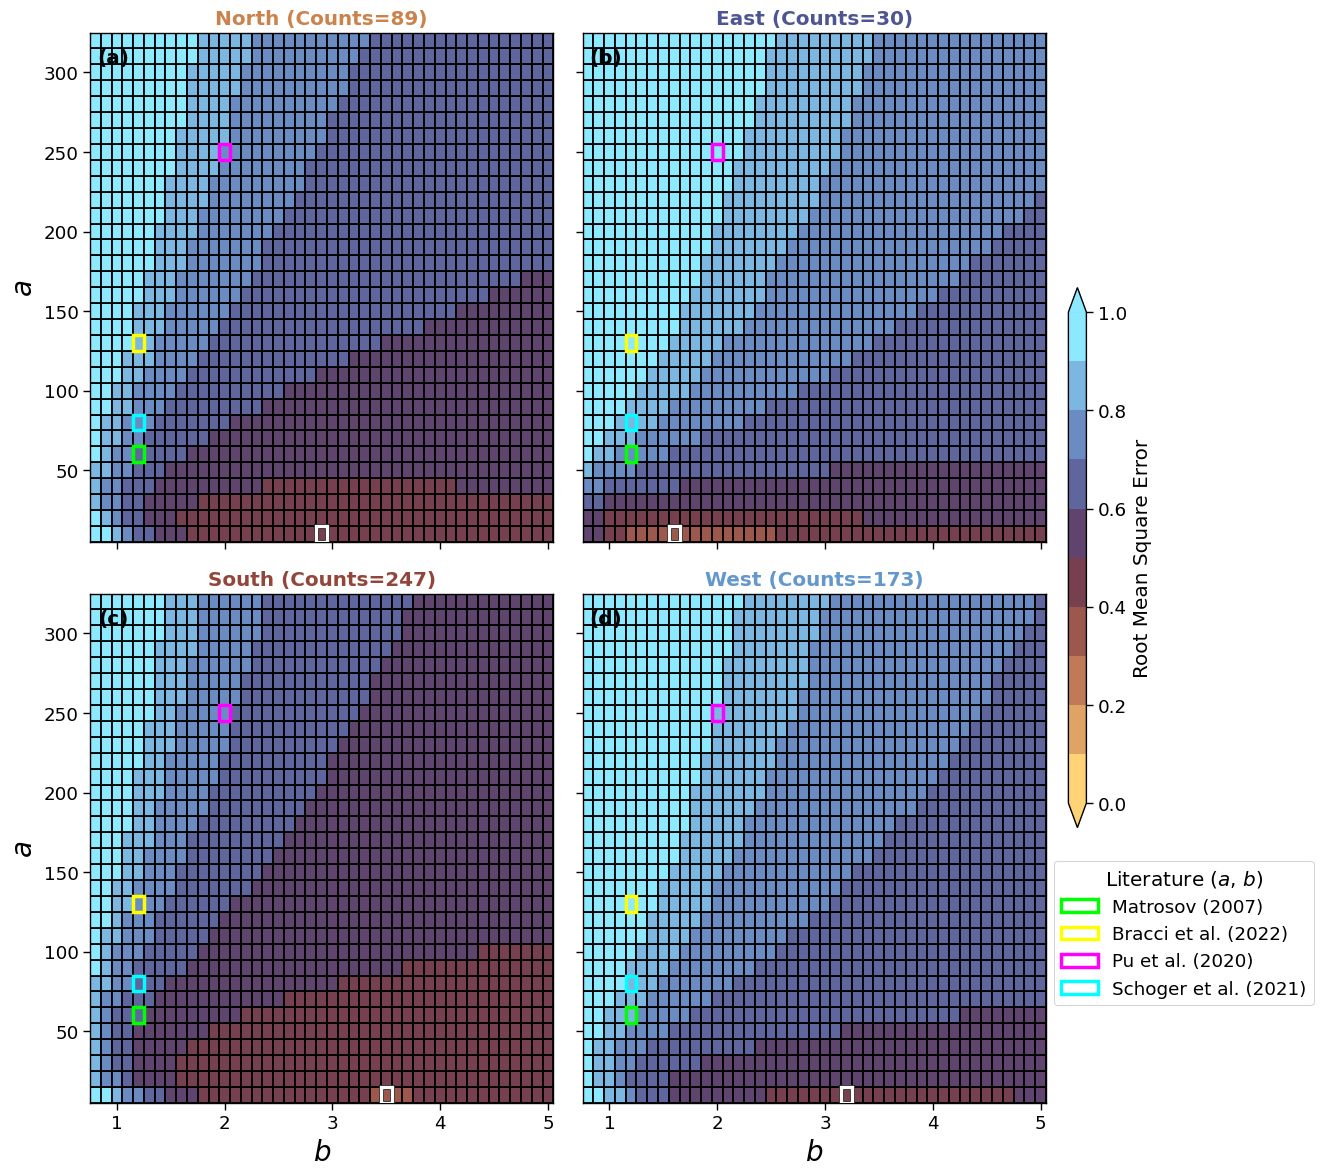

In [31]:
# wind sector seperation
plt_chessboard(df_rmse['wind_direction_sector'], counts['wind_direction_sector'], cbar_label="Root Mean Square Error", category=['North', 'East', 'South', 'West'])

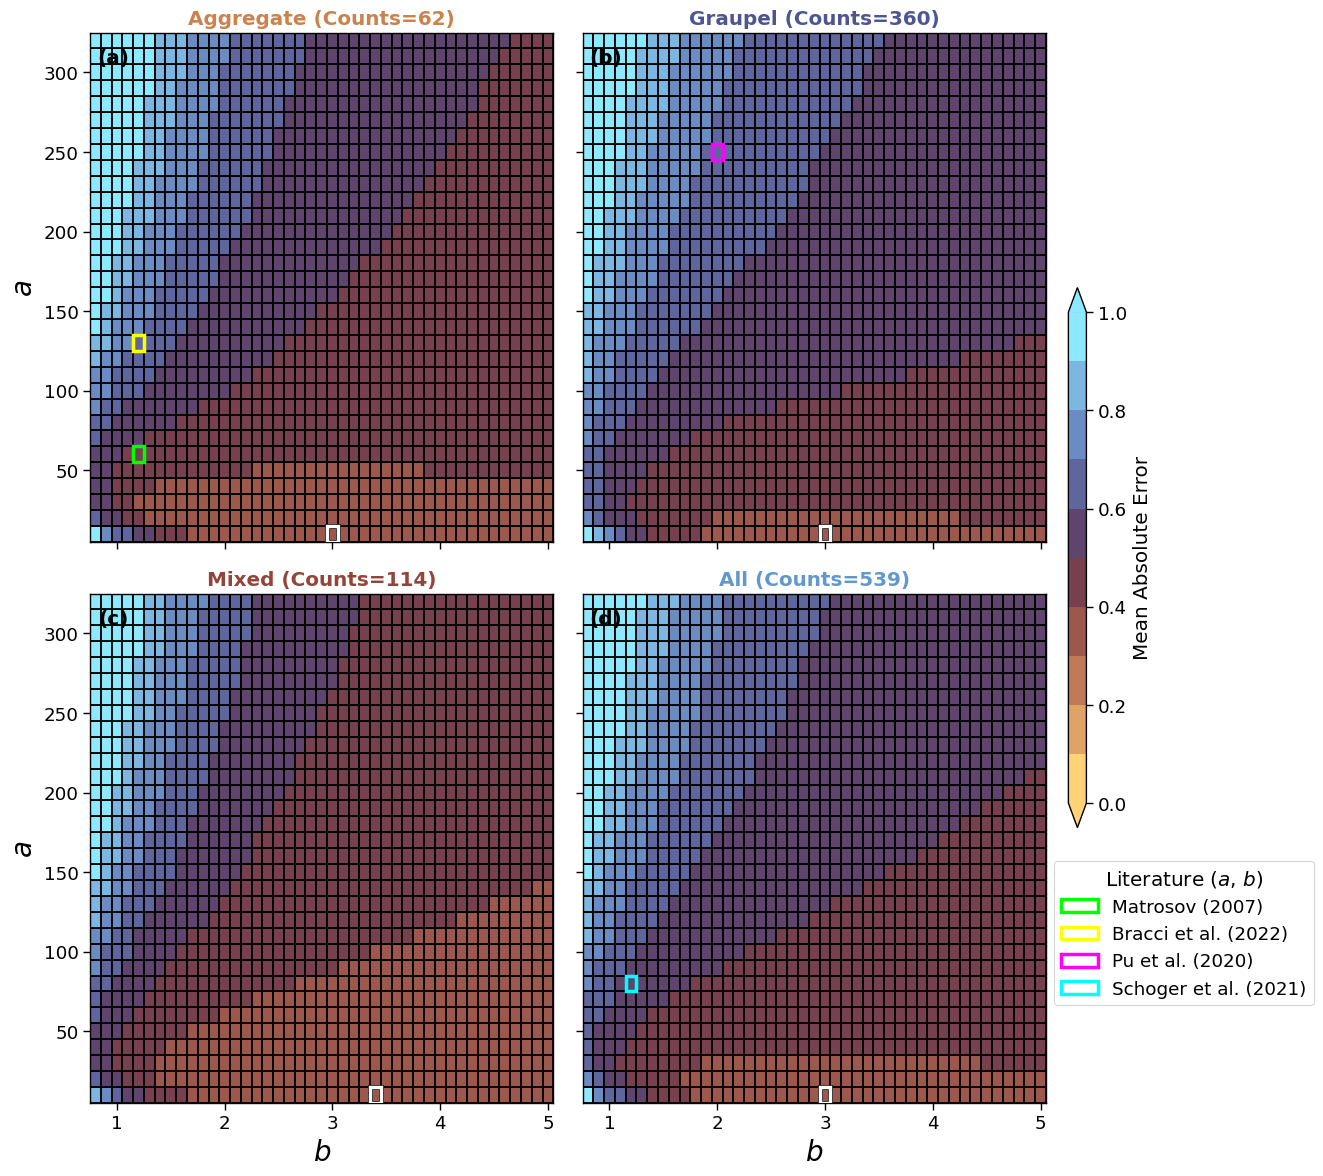

In [32]:
plt_chessboard(df_mae['snowflake_class'], counts['snowflake_class'], cbar_label="Mean Absolute Error", category=['aggregate', 'graupel', 'mixed', 'all'])

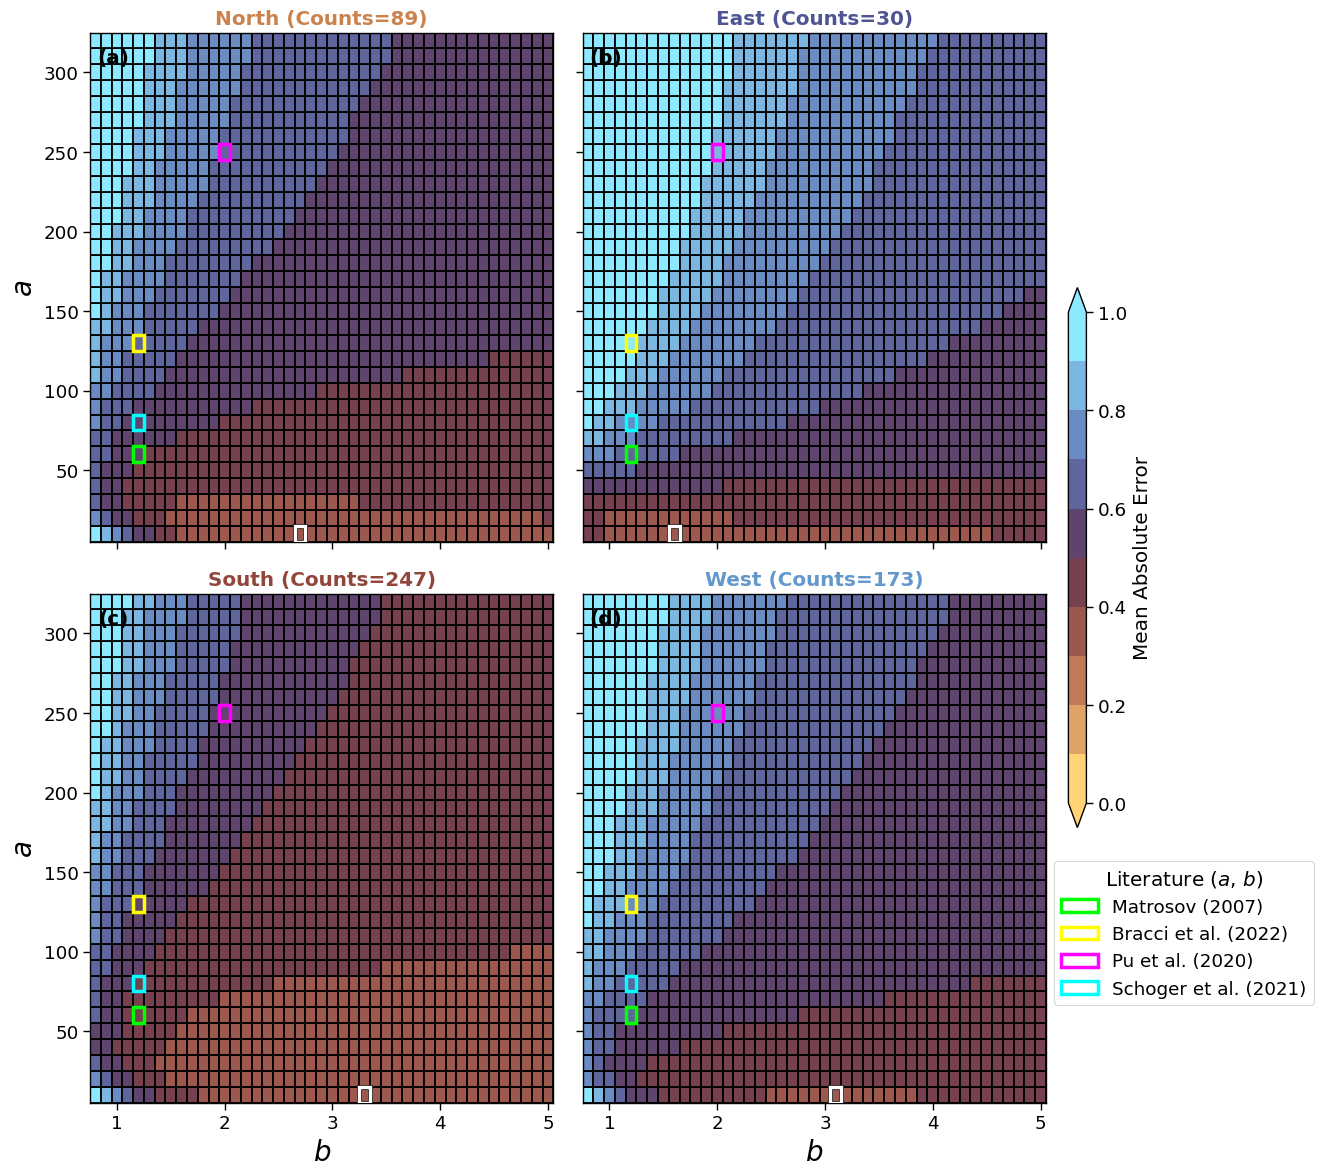

In [33]:
plt_chessboard(df_mae['wind_direction_sector'], counts['wind_direction_sector'], cbar_label="Mean Absolute Error", category=['North', 'East', 'South', 'West'])

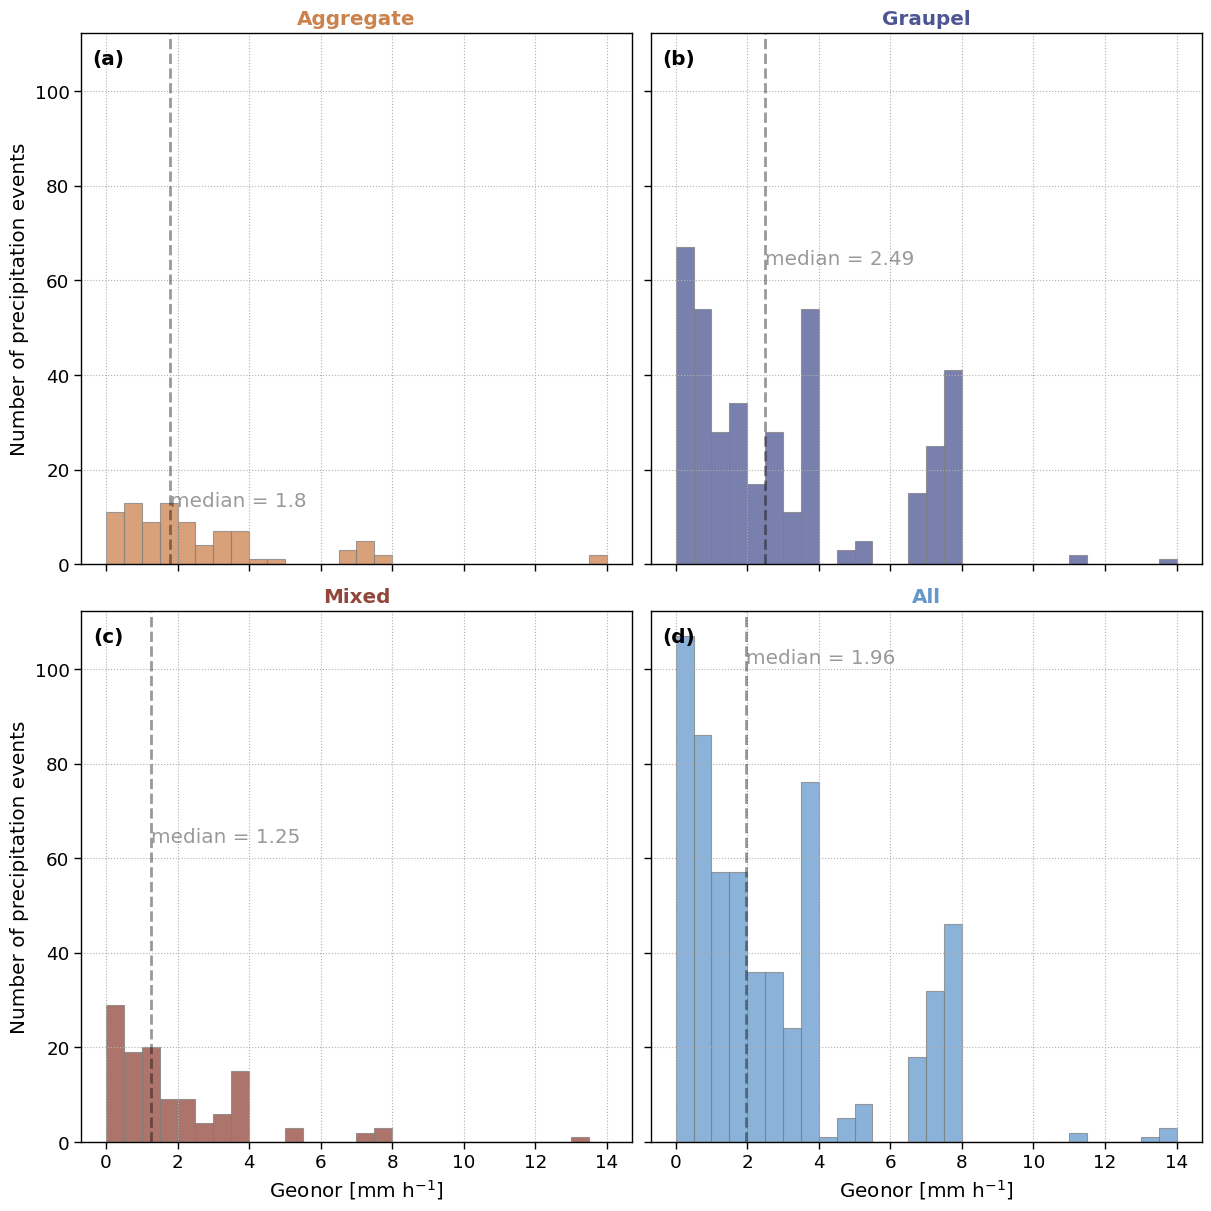

In [34]:
fig, axs = plt.subplots(2,2, figsize=(12,12), sharex=True, sharey=True, constrained_layout=True)

for (i, ax), class_key in zip(enumerate(axs.flatten()), ['aggregate', 'graupel', 'mixed', 'all']):
    SWE_obs = sf_class_dict[class_key]['rate_mm_h'].values
    # keep only finit values
    SWE_obs = SWE_obs[np.isfinite(SWE_obs)]
    # calculate quantiles
    q = np.percentile(SWE_obs, [25, 50, 75])
    iqr = q[2] - q[0]

    ax.hist(SWE_obs, bins=np.arange(0., 14.1,0.5), color=custom_colors[class_key], edgecolor="grey", alpha=0.75)
    # for swe in q:
    #     ax.axvline(swe, color="k", ls="--", alpha=0.4)
    ax.axvline(q[1], color="k", ls="--", alpha=0.4)
    ax.text(q[1], ax.get_ylim()[1]*0.9, f"median = {q[1].round(2)}", color="k", alpha=0.4)

    ax.grid(True, ls=':')

    ax.set_title(f"{class_key}".title(), fontweight='bold', color=custom_colors[class_key])
    ax.text(0.05, 0.95, fct.fig_label[i], fontweight="bold", horizontalalignment="center", verticalalignment='center', transform = ax.transAxes)
    

for i in range(2):
    axs[i, 0].set_ylabel("Number of precipitation events", )#fontsize=20)
    axs[1, i].set_xlabel("Geonor [mm h$^{{-1}}$]",)# fontsize=20)

# plt.tight_layout(rect=[0, 0, 0.9, 1])   # leave room for cbars


In [35]:
def extract_best_ab(df_metrics):
    """
    Extract best (a,b) per [metric_key][class_key] from stacked DataFrames.
    Returns: dict[metric_key][class_key] = (a, b)
    """
    return {
        metric_key: {
            class_key: df.stack().idxmin() for class_key, df in class_dict.items() if class_key != 'pristine'
        }
        for metric_key, class_dict in df_metrics.items()
    }

In [36]:
rmse_ab = extract_best_ab(df_rmse)
mae_ab = extract_best_ab(df_mae)

In [37]:
rmse_cfg = {
    "habit": {
        'aggregate': rmse_ab["snowflake_class"]["aggregate"],
        'graupel': rmse_ab["snowflake_class"]["graupel"],
        'mixed': rmse_ab["snowflake_class"]["mixed"],
        },
    "habit_high_precipitation": {
        'aggregate': rmse_ab["high_precipitation"]["aggregate"],
        'graupel': rmse_ab["high_precipitation"]["graupel"],
        'mixed': rmse_ab["high_precipitation"]["graupel"],
        },
    "habit_low_precipitation": {
        'aggregate': rmse_ab["low_precipitation"]["aggregate"],
        'graupel': rmse_ab["low_precipitation"]["graupel"],
        'mixed': rmse_ab["low_precipitation"]["mixed"],
        }
}

In [38]:
mae_cfg = {
    "habit": {
        'aggregate': mae_ab["snowflake_class"]["aggregate"],
        'graupel': mae_ab["snowflake_class"]["graupel"],
        'mixed': mae_ab["snowflake_class"]["mixed"],
        },
    "habit_high_precipitation": {
        'aggregate': mae_ab["high_precipitation"]["aggregate"],
        'graupel': mae_ab["high_precipitation"]["graupel"],
        'mixed': mae_ab["high_precipitation"]["graupel"],
        },
    "habit_low_precipitation": {
        'aggregate': mae_ab["low_precipitation"]["aggregate"],
        'graupel': mae_ab["low_precipitation"]["graupel"],
        'mixed': mae_ab["low_precipitation"]["mixed"],
        }
}

In [39]:
wind_rmse_cfg = {
    "wind": {
        'North': rmse_ab["wind_direction_sector"]["North"],
        'East': rmse_ab["wind_direction_sector"]["East"],
        'South': rmse_ab["wind_direction_sector"]["South"],
        'West': rmse_ab["wind_direction_sector"]["West"],
        },
    "wind_high_precipitation": {
        'North': rmse_ab["high_precipitation"]["North"],
        'East': rmse_ab["high_precipitation"]["East"],
        'South': rmse_ab["high_precipitation"]["South"],
        'West': rmse_ab["high_precipitation"]["West"],
        },
    "wind_low_precipitation": {
        'North': rmse_ab["low_precipitation"]["North"],
        'East': rmse_ab["low_precipitation"]["East"],
        'South': rmse_ab["low_precipitation"]["South"],
        'West': rmse_ab["low_precipitation"]["West"],
        }
}

In [40]:
wind_mae_cfg = {
    "wind": {
        'North': mae_ab["wind_direction_sector"]["North"],
        'East': mae_ab["wind_direction_sector"]["East"],
        'South': mae_ab["wind_direction_sector"]["South"],
        'West': mae_ab["wind_direction_sector"]["West"],
        },
    "wind_high_precipitation": {
        'North': mae_ab["high_precipitation"]["North"],
        'East': mae_ab["high_precipitation"]["East"],
        'South': mae_ab["high_precipitation"]["South"],
        'West': mae_ab["high_precipitation"]["West"],
        },
    "wind_low_precipitation": {
        'North': mae_ab["low_precipitation"]["North"],
        'East': mae_ab["low_precipitation"]["East"],
        'South': mae_ab["low_precipitation"]["South"],
        'West': mae_ab["low_precipitation"]["West"],
        }
}

In [41]:
campaign_rmse_cfg = {
    "campaign": {
        'all': rmse_ab["snowflake_class"]["all"],  
    },
    "campaign_high_precipitation": {
        'all': rmse_ab["high_precipitation"]["all"],  
    },
    "campaign_low_precipitation": {
        'all': rmse_ab["low_precipitation"]["all"],  
    }
}

In [42]:
campaign_mae_cfg = {
    "campaign": {
        'all': mae_ab["snowflake_class"]["all"],  
    },
    "campaign_high_precipitation": {
        'all': mae_ab["high_precipitation"]["all"],  
    },
    "campaign_low_precipitation": {
        'all': mae_ab["low_precipitation"]["all"],  
    }
}

In [43]:
def build_pp(cfg, source_dict, delta_h):

    series = []
    for cls, (a, b) in cfg.items():
        key = f"S_{a}_{b}_400_mm_h"
        s = source_dict[cls][key]
        series.append(s)
    pp = pd.concat(series).sort_index()
    return pp * delta_h.loc[pp.index]

In [44]:
delta_h = sf_class_dict['all']['delta_h']
rmse_series = {}
mae_series = {}
for name, cfg in rmse_cfg.items():
    rmse_series[name] = build_pp(cfg, sf_class_dict, delta_h)
for name, cfg in mae_cfg.items():
    mae_series[name] = build_pp(cfg, sf_class_dict, delta_h)

rmse_wind_series = {}
mae_wind_series = {}
for name, cfg in wind_rmse_cfg.items():
    rmse_wind_series[name] = build_pp(cfg, wd_sector_dict, delta_h)
for name, cfg in wind_mae_cfg.items():
    mae_wind_series[name] = build_pp(cfg, wd_sector_dict, delta_h)

rmse_campaign_series = {}
mae_campaign_series = {}
for name, cfg in campaign_rmse_cfg.items():
    rmse_campaign_series[name] = build_pp(cfg, sf_class_dict, delta_h)
for name, cfg in campaign_mae_cfg.items():
    mae_campaign_series[name] = build_pp(cfg, sf_class_dict, delta_h)

In [45]:
def plt_cum(ax, series, label, color, ls):
    ax.plot(series.cumsum().fillna(method="ffill"), label=label, color=color, linestyle=ls, linewidth=3)

/tmp/ipykernel_4133448/4222197248.py:53: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(rect=[0, 0, 0., 1])   # leave room for cbars
/tmp/ipykernel_4133448/4222197248.py:53: UserWarning: The figure layout has changed to tight
  plt.tight_layout(rect=[0, 0, 0., 1])   # leave room for cbars


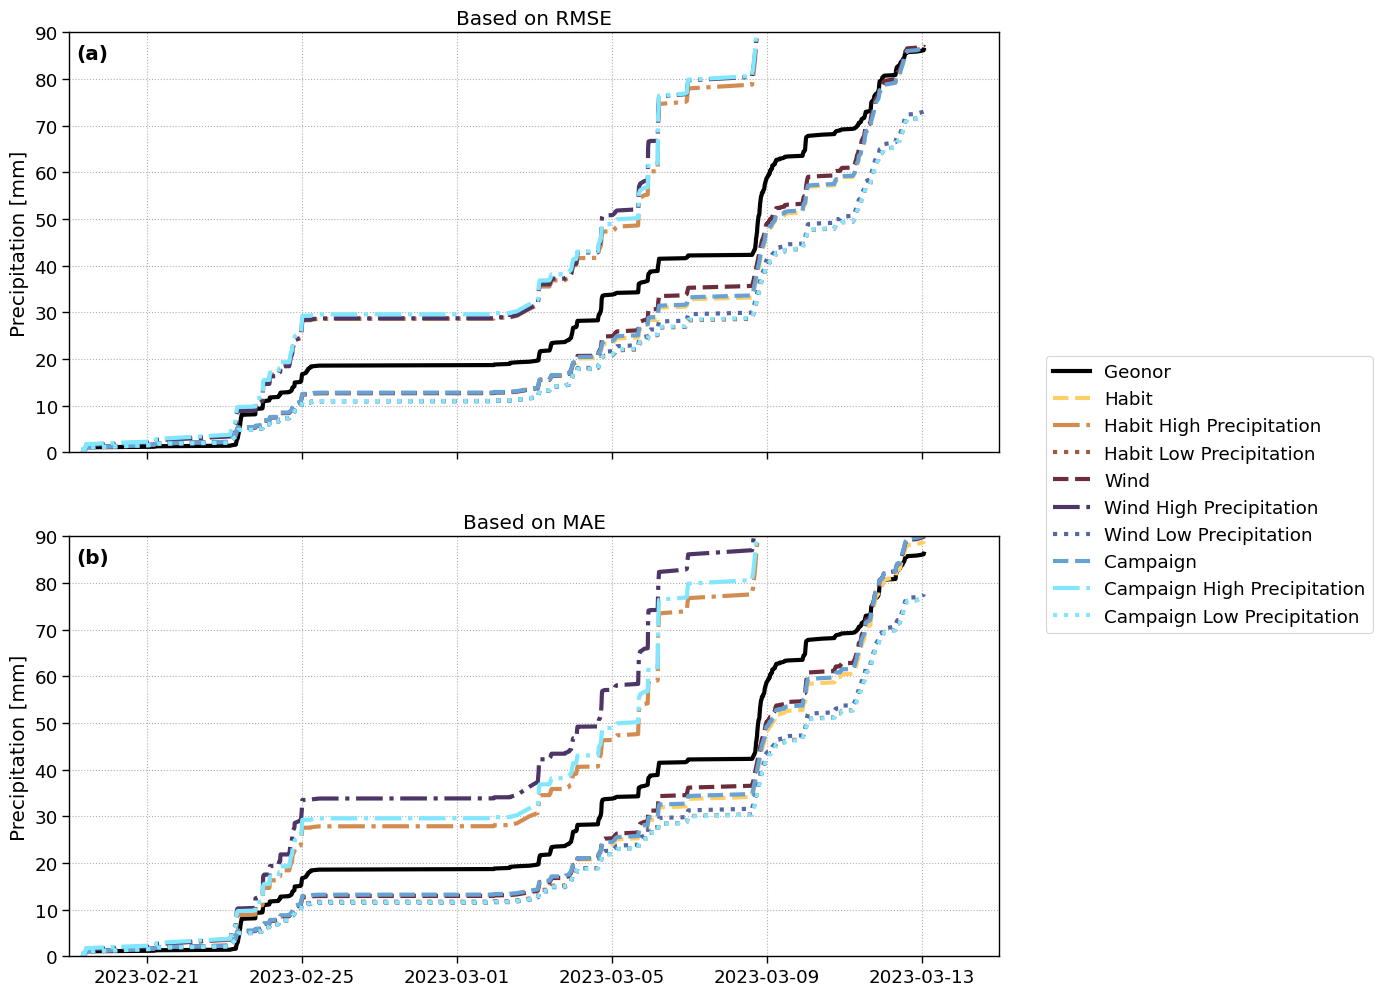

In [46]:
fig, axs = plt.subplots(2, 1, figsize=(12,12), sharex=True, sharey=True, constrained_layout=True)

custom_cmap = LinearSegmentedColormap.from_list(
'Custom cmap', cmaplist, 8)

plt_cum(axs[0], sf_class_dict['all']['rate_mm_h']*delta_h, "Geonor", "k", "-")
plt_cum(axs[1], sf_class_dict['all']['rate_mm_h']*delta_h, "Geonor", "k", "-")

# plt_cum(axs[0], sf_class_dict[])

styles = [
    ("habit", "--"),
    ("habit_high_precipitation", "-."),
    ("habit_low_precipitation", ":") 
]
for i, (name, ls) in enumerate(styles):
    plt_cum(axs[0], rmse_series[name], name.replace("_", " ").title(), custom_cmap(i), ls)
    plt_cum(axs[1], mae_series[name], name.replace("_", " ").title(), custom_cmap(i), ls)

wind_styles = [
    ("wind", "--"),
    ("wind_high_precipitation", "-."),
    ("wind_low_precipitation", ":") 
]
for i, (name, ls) in enumerate(wind_styles, start=3):
    plt_cum(axs[0], rmse_wind_series[name], name.replace("_", " ").title(), custom_cmap(i), ls)
    plt_cum(axs[1], mae_wind_series[name], name.replace("_", " ").title(), custom_cmap(i), ls)

campaign_styles = [
    ("campaign", "--"),
    ("campaign_high_precipitation", "-."),
    ("campaign_low_precipitation", ":") 
]
for i, (name, ls) in enumerate(campaign_styles, start=6):
    plt_cum(axs[0], rmse_campaign_series[name], name.replace("_", " ").title(), custom_cmap(i), ls)
    plt_cum(axs[1], mae_campaign_series[name], name.replace("_", " ").title(), custom_cmap(i), ls)

date_form = DateFormatter("%Y-%m-%d")
for (i, ax), title in zip(enumerate(axs), ["Based on RMSE", "Based on MAE"]):
    ax.set(title=title)
    ax.text(0.025, 0.95, fct.fig_label[i], fontweight="bold", horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)
    ax.xaxis.grid(which="both", ls=":")
    ax.yaxis.grid(which="both", ls=":")
    ax.tick_params(axis="x", labelrotation=0)
    plt.setp(ax.get_xticklabels(), horizontalalignment='center')
    ax.xaxis_date()
    ax.xaxis.set_major_formatter(date_form)
    ax.set_xlim([pd.Timestamp("'2023-02-19' 00:00:00"), pd.Timestamp(f"'2023-03-15' 00:00:00")])
    ax.set_ylabel("Precipitation [mm]")
    ax.set_ylim([0,90])

axs[1].legend(loc='center left', bbox_to_anchor=(1.04, 1.1))
plt.tight_layout(rect=[0, 0, 0., 1])   # leave room for cbars


In [47]:
def plot_literature_lines(ax, class_key, category_set, x_line):
    """
    ax           : matplotlib axis
    class_key    : current subplot category (e.g. 'aggregate', 'North')
    category_set : tuple used in LIT_PLACEMENT keys
    x_line       : x grid (logspace)
    """

    if category_set not in LIT_PLACEMENT:
        return

    placement = LIT_PLACEMENT[category_set]

    if class_key not in placement:
        return

    for lit_id in placement[class_key]:
        lit = LITERATURE_BOXES[lit_id]

        a = lit["a"]
        b = lit["b"]
        color = lit["color"]
        label = lit["label"]

        y = a * x_line**b

        ax.plot(
            x_line, y,
            color=color,
            linestyle="--",
            linewidth=1.6,
            alpha=0.9,
            label=label
        )


In [48]:
row_cfg = {
    0: {# first row
        "main": ("snowflake_class", "-"),
        "extra": [("high_precipitation", "-."),
                  ("low_precipitation", ":")]},
    1: {# second row
        "main": ("wind_direction_sector", "-"),
        "extra": [("high_precipitation", "-."),
                  ("low_precipitation", ":")]},
}

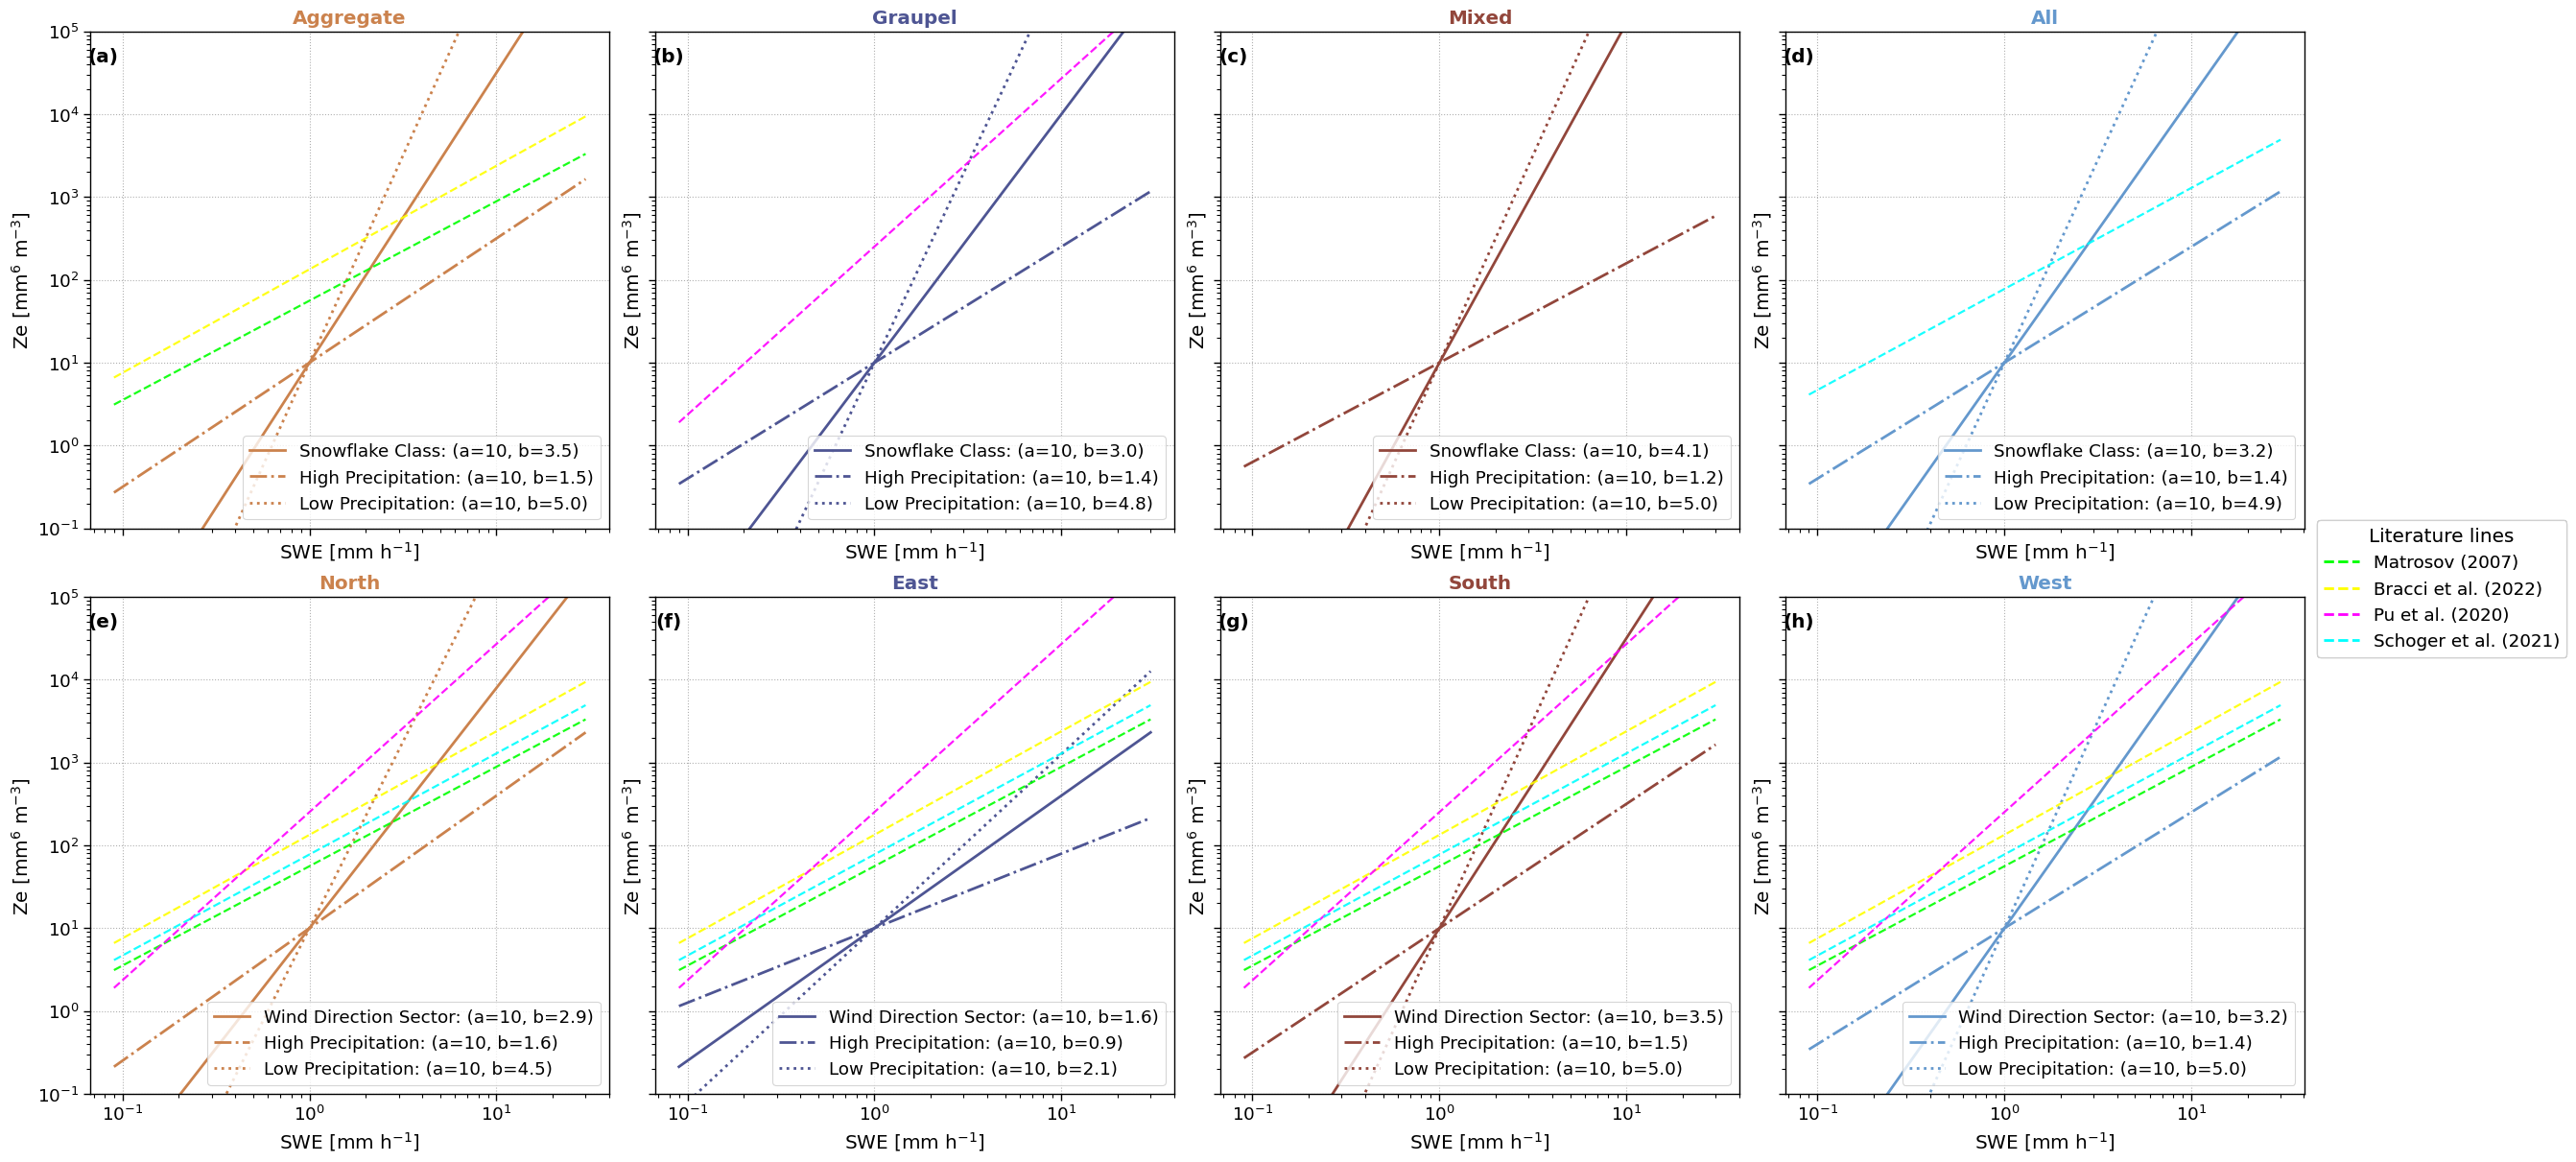

In [ ]:
fig, axsm = plt.subplots(2, 4, figsize=(24,12), sharex=True, sharey=True, constrained_layout=True)
rows = [
    ["aggregate", "graupel", "mixed", "all", ],
    ['North', 'East', 'South', 'West']
]


custom_c = [LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(1),
                 LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(4),
                 LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(2),
                 LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(5)]
# Generate lines
x_line = np.logspace(np.log10(0.09), np.log10(30), 300)
y_line = 56*x_line**1.2

# 1-1 line
x= np.linspace(0,50, 100)
y=x
for r, row_cats in enumerate(rows):
        for c, class_key in enumerate(row_cats):
                ax = axsm[r, c]
                i = r*4 + c # index for fig label

                ax.text(0.025, 0.95, fct.fig_label[i], fontweight="bold", horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)
                ax.grid(True, ls=":", which='both')
                ax.set_xscale('log')
                ax.set_yscale('log')
                ax.set(xlabel="SWE [mm h$^{-1}$]", ylabel="Ze [mm${^6}$ m$^{-3}]$")
                ax.set_title(f"{class_key}".title(), fontweight='bold', color=custom_c[c])
                ax.set_ylim([10**(-1), 10**5])


                cfg = row_cfg[r]
                main_name, main_ls = cfg["main"]
                a_val, b_val = rmse_ab[main_name][class_key]
                label_name = main_name.replace("_", " ").title()
                y_line = a_val * x_line**b_val

                ax.plot(x_line, y_line, label=f"{label_name}: (a={a_val}, b={b_val})", color=custom_c[c], linestyle=main_ls)

                # precipitation relations
                for name, ls in cfg["extra"]:
                        a_val, b_val = rmse_ab[name][class_key]
                        label_name = name.replace("_", " ").title()
                        y_line = a_val * x_line**b_val
                        ax.plot(x_line, y_line, label=f"{label_name}: (a={a_val}, b={b_val})", color=custom_c[c], linestyle=ls)
                ax.legend(loc='lower right')
              

                if r == 0:
                        category_set = ("aggregate", "graupel", "mixed", "all")
                elif r== 1:
                        category_set = ('North', 'East', 'South', 'West')
                # all literature lines
                plot_literature_lines(ax, class_key, category_set, x_line)
                
                lit_handles = [
                        Line2D(
                                [0], [0],
                                color=box["color"],
                                linestyle="--",
                                linewidth=2,
                                label=box["label"]
                        )
                        for box in LITERATURE_BOXES.values()
                        ]

                fig.legend(
                        handles=lit_handles,
                        loc='upper left',
                        bbox_to_anchor=(1.0, 0.56),   # adjust as needed
                        frameon=True,
                        title=r"Literature lines"
                        )
                


In [50]:
from matplotlib.animation import FuncAnimation, FFMpegWriter

In [51]:
# Best (a,b) from RMSE extraction
a_best, b_best = rmse_ab['snowflake_class']['all']
save_path = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/ANX_obs_daily/animation/ab_ensemble_rmse_b3.2.mp4"
fps = 20 # presentation quality (15-24 fps range)

# ----------------------------
# Data
# ----------------------------
x_obs = sf_class_dict['all']['rate_mm_h']  # SWE_obs
# SWE_retrieved is accessed dynamically per (a,b)

# ----------------------------
# Precompute RMSE lookup
# ----------------------------
rmse_map = df_rmse['snowflake_class']['all']  # DataFrame indexed by a,b
# assumes index=a, columns=b 


In [52]:
# ----------------------------
# Build frame sequence (stop at minimum RMSE)
# ----------------------------
frames = []
stop = False
for a in a_range[::-1]:
    a = int(a)
    for b in np.arange(3.2, 3.3,0.1):#b_range:
        b = b.round(2)
        frames.append((a, b))
        if a == a_best and np.isclose(b, b_best):
            stop = True
            break
    if stop:
        break

print(f"Total frames: {len(frames)}")

Total frames: 32


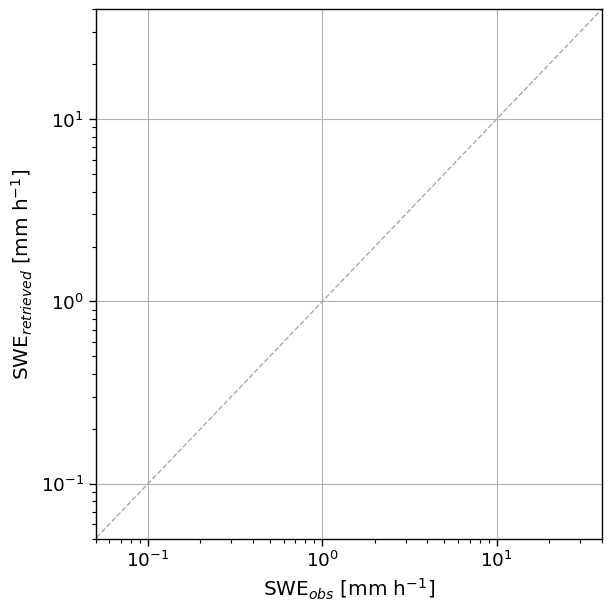

In [ ]:
# ----------------------------
# Figure
# ----------------------------
fig, axs = plt.subplots(1,1, figsize=(6,6), sharex=True, sharey=True, constrained_layout=True)

sc = axs.scatter([],[], color=custom_colors['all'], s=15, alpha=0.7)

# plot 1:1 line
x_line = np.linspace(0.01, 40, 100)
axs.plot(x_line, x_line, linestyle='--', color='darkgrey', lw=1)

axs.set_xscale('log')
axs.set_yscale('log')
axs.grid(True, ls=':', which='both')
axs.set(xlabel="SWE$_{obs}$ [mm h$^{-1}$]", ylabel="SWE$_{retrieved}$ [mm h$^{-1}$]")

# fixed limits (important for visiual stability)
axs.set_xlim(0.05, 40)
axs.set_ylim(0.05, 40)

title = axs.set_title("", fontweight='bold', color=custom_colors['all'])

# dynamic annotation box
text_box = ax.text(0.02, 0.98, "", transform=axs.transAxes, va='top', ha='left', fontsize=11, bbox=dict(boxstyle="round", fc="white", ec="0.5", alpha=0.9))

         

In [54]:
# ----------------------------
# Animation update function
# ----------------------------
def update(frame_idx):
    a, b = frames[frame_idx]

    y_ret = sf_class_dict['all'][f"S_{a}_{b}_400_mm_h"]

    # update scatter
    sc.set_offsets(np.c_[x_obs.values, y_ret.values])

    # RMSE value
    try:
        rmse_val = rmse_map.loc[a, b]
    except:
        rmse_val = np.nan

    # update title
    title.set_text(f"All crystals — a = {a},  b = {b}")

    # update annotation
    text_box.set_text(
        f"a = {a}\n"
        f"b = {b:.2f}\n"
        f"RMSE = {rmse_val:.4f}"
    )

    return sc, title, text_box



In [55]:
# # ----------------------------
# # Build animation
# # ----------------------------
# anim = FuncAnimation(fig, update, frames=len(frames), interval=1000/fps, blit=False)

# # ----------------------------
# # Save MP4
# # ----------------------------
# writer = FFMpegWriter(fps=fps, bitrate=1800)
# anim.save(save_path, writer=writer)
# plt.close(fig)

# print(f"Saved animation to:\n{save_path}")

In [56]:
file_paths = sorted(glob(os.path.join(OUTPUT_DATA_DIR, f'ANX_obs', f'10min_filled_obs_hatpro_airport_WD_WS_T_{site}_{year}*.nc')))

In [57]:
datasets = [xr.open_dataset(file_path) for file_path in file_paths]
# combine them 
ds_23 = xr.combine_by_coords(datasets,)

In [58]:
Ze_400 = ds_23['Ze_400m']

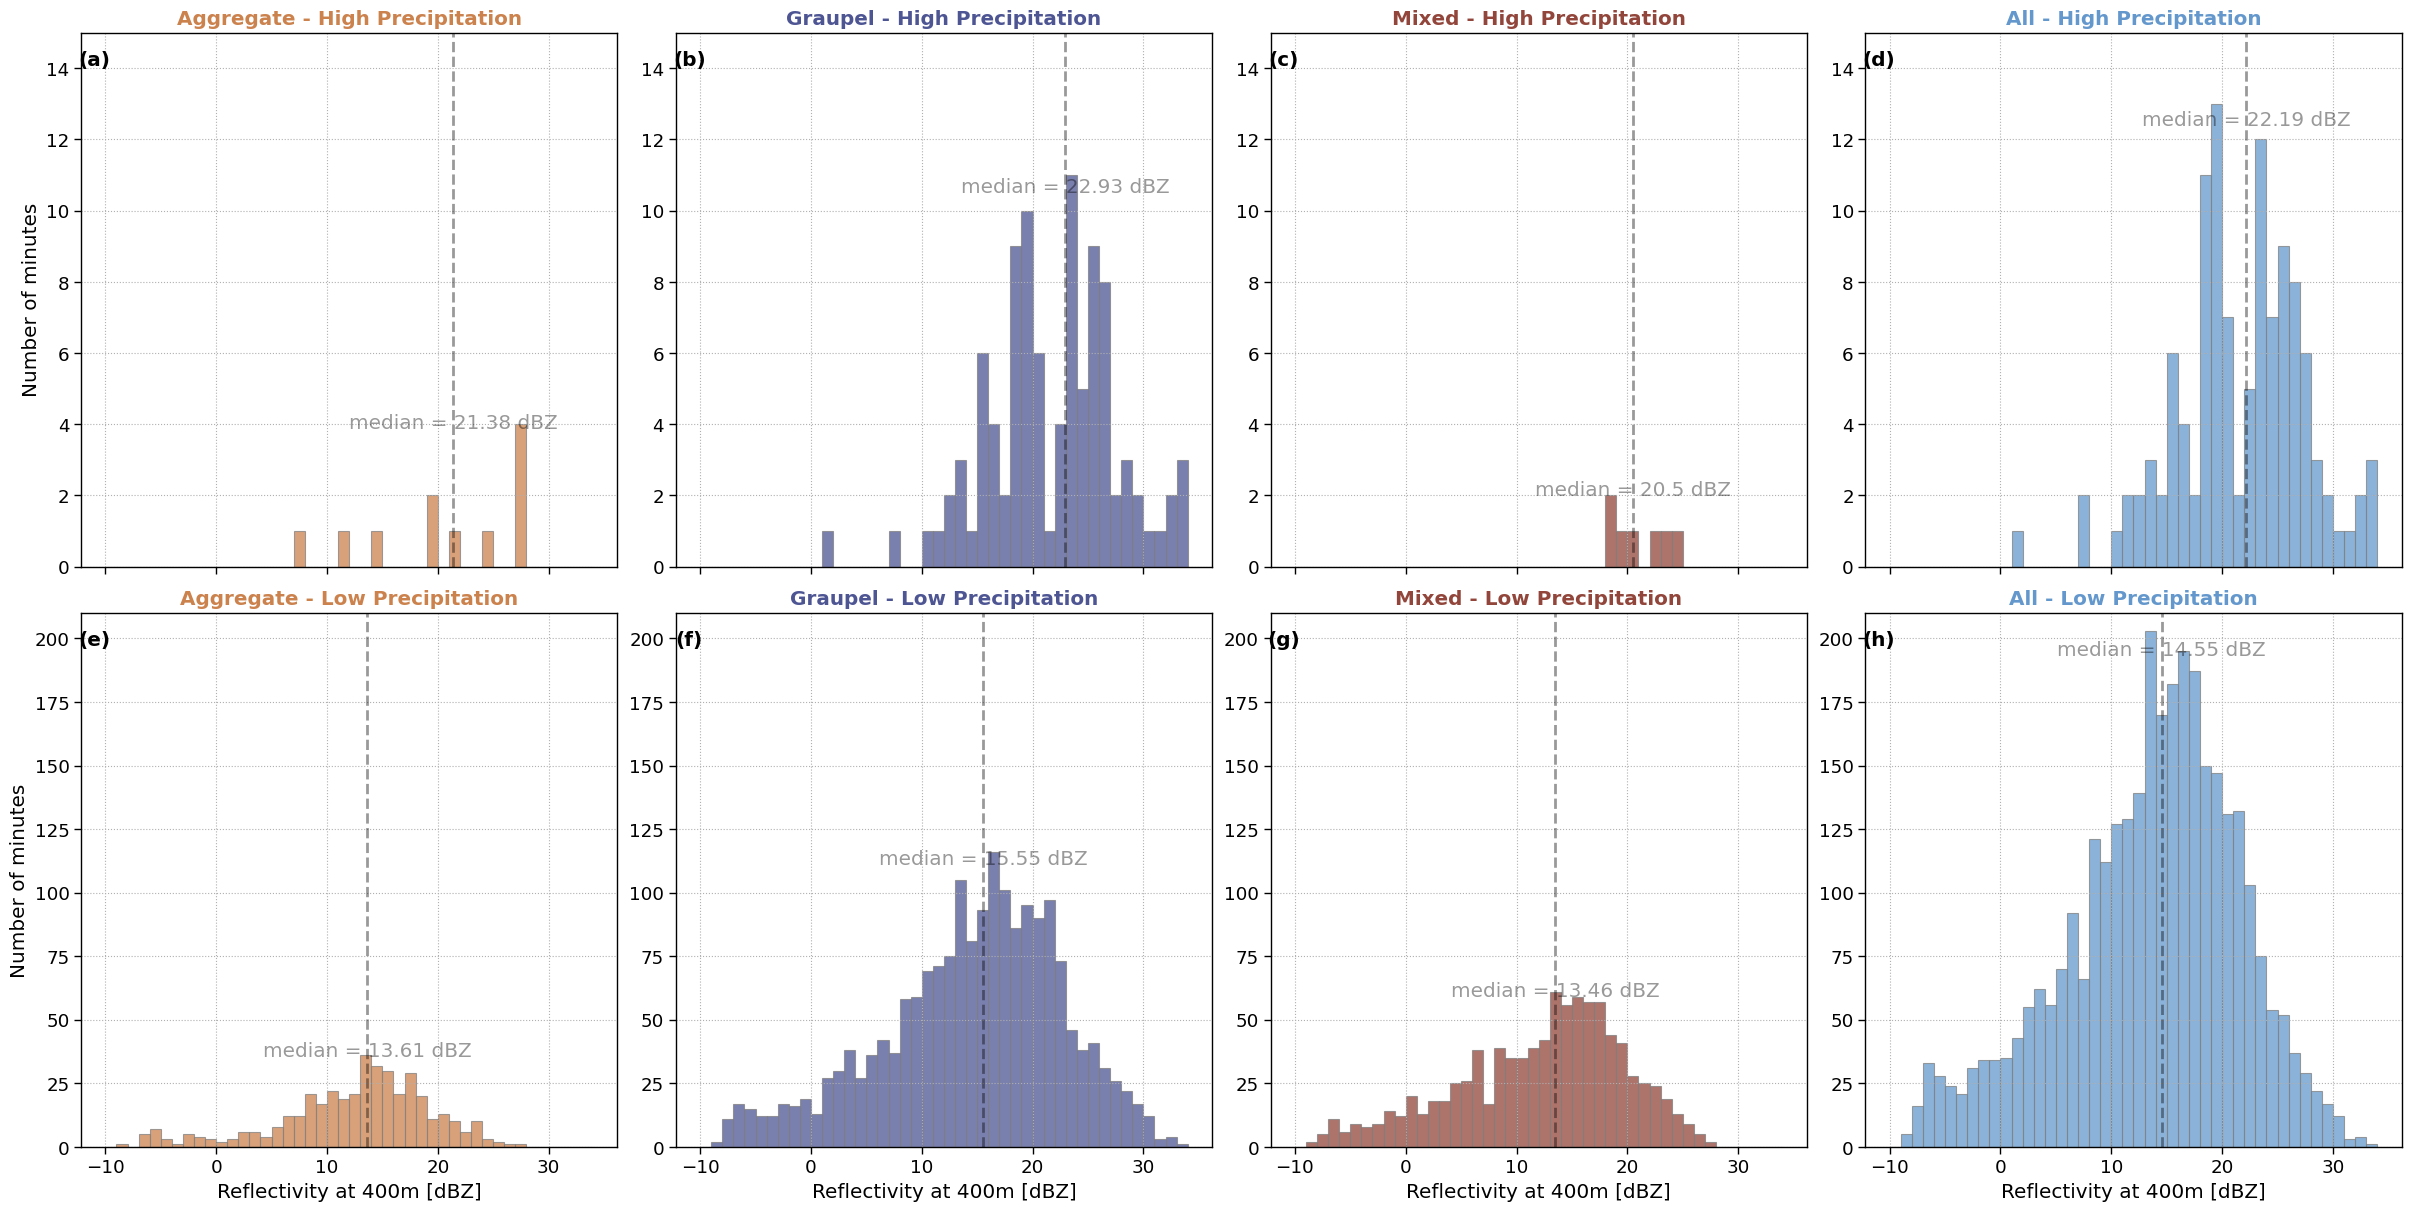

In [59]:
precip = {"high_precipitation": heavy_precip, "low_precipitation":low_precip}
fig, axsm = plt.subplots(2,4, figsize=(24,12), sharex=True, constrained_layout=True)

rows = [['aggregate', 'graupel', 'mixed', 'all'],['aggregate', 'graupel', 'mixed', 'all']]


for (r, row_cats), (pp_key, pp) in zip(enumerate(rows), precip.items()):
        
        for c, class_key in enumerate(row_cats):
            ax = axsm[r, c]
            i = r*4 + c # index for fig label

            ax.text(0.025, 0.95, fct.fig_label[i], fontweight="bold", horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)
            ax.grid(True, ls=":")
            # ax.set_xscale('log')
            # ax.set_yscale('log')
            # ax.set(xlabel=, ylabel="Number of minutes")
            pp_key = pp_key.replace("_", " ").title()
            ax.set_title(f"{class_key} - {pp_key}".title(), fontweight='bold', color=custom_c[c])
            # ax.set_ylim([10**(-1), 10**5])

            Ze_400_obs = fct.get_ds_in_precip_event(pp[class_key], Ze_400)
            # keep only finit values
            Ze_400_obs = Ze_400_obs[np.isfinite(Ze_400_obs)]
            # calculate quantiles
            q = np.percentile(Ze_400_obs, [25, 50, 75])
            iqr = q[2] - q[0]
            ax.hist(Ze_400_obs, bins=np.arange(-10, 35,1), color=custom_colors[class_key], edgecolor="grey", alpha=0.75)

            ax.axvline(q[1], color="k", ls="--", alpha=0.4)
            ax.text(q[1], ax.get_ylim()[1]*0.9, f"median = {q[1].round(2)} dBZ", color="k", alpha=0.4, horizontalalignment='center', verticalalignment='bottom')

            if r == 0:
                ax.set_ylim(0,15)
                
            elif r == 1:
                 ax.set_ylim(0, 210)
                 ax.set_xlabel("Reflectivity at 400m [dBZ]")
            if c == 0:
                 ax.set_ylabel("Number of minutes")
   

In [60]:
category = ['aggregate', 'graupel', 'mixed', 'all']

In [83]:
def plt_scatter_SWEobs_SWEret_4x4(rmse_ab, df_rmse, df, category):
    custom_colors = {  
                     category[0]: LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(1),  
                     category[1]:LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(4),   
                     category[2]: LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(2),
                     category[3]: LinearSegmentedColormap.from_list('Custom cmap', cmaplist, 7)(5),
}

    fig, axs = plt.subplots(2,2, figsize=(12,12), sharex=True, sharey=True, constrained_layout=True)

    for (i, ax), class_key in zip(enumerate(axs.flatten()), category):
        a, b = rmse_ab[class_key]

        rmse_val = df_rmse[class_key].loc[a, b]
        x_obs = df[class_key]['rate_mm_h']
        y_ret = df[class_key][f"S_{a}_{b}_400_mm_h"]
        sc = ax.scatter(x_obs, y_ret, color=custom_colors[class_key], s=15, alpha=0.7)


        
        # plot 1:1 line
        x_line = np.linspace(0.01, 40, 100)
        ax.plot(x_line, x_line, linestyle='--', color='darkgrey', lw=1)

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.grid(True, ls=':', which='both')


        # fixed limits (important for visiual stability)
        ax.set_xlim(0.05, 40)
        ax.set_ylim(0.05, 40)
        
        ax.text(0.025, 0.95, fct.fig_label[i], fontweight="bold", horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)

        title = ax.set_title("", fontweight='bold', color=custom_colors[class_key])
        class_key = class_key.replace("_", " ").title()
        title.set_text(f"{class_key} — a = {a},  b = {b}")

        # dynamic annotation box
        text_box = ax.text(0.075, 0.98, "", 
                transform=ax.transAxes, va='top', ha='left', fontsize=11, bbox=dict(boxstyle="round", fc="white", ec="0.5", alpha=0.9))

        
        # update annotation
        text_box.set_text(
                f"a = {a}\n"
                f"b = {b:.2f}\n"
                f"RMSE = {rmse_val:.4f}"
            )

    for i in range(2):
        axs[i, 0].set_ylabel("SWE$_{retrieved}$ [mm h$^{-1}$]", )#fontsize=20)
        axs[1, i].set_xlabel("SWE$_{obs}$ [mm h$^{-1}$]",)# fontsize=20)

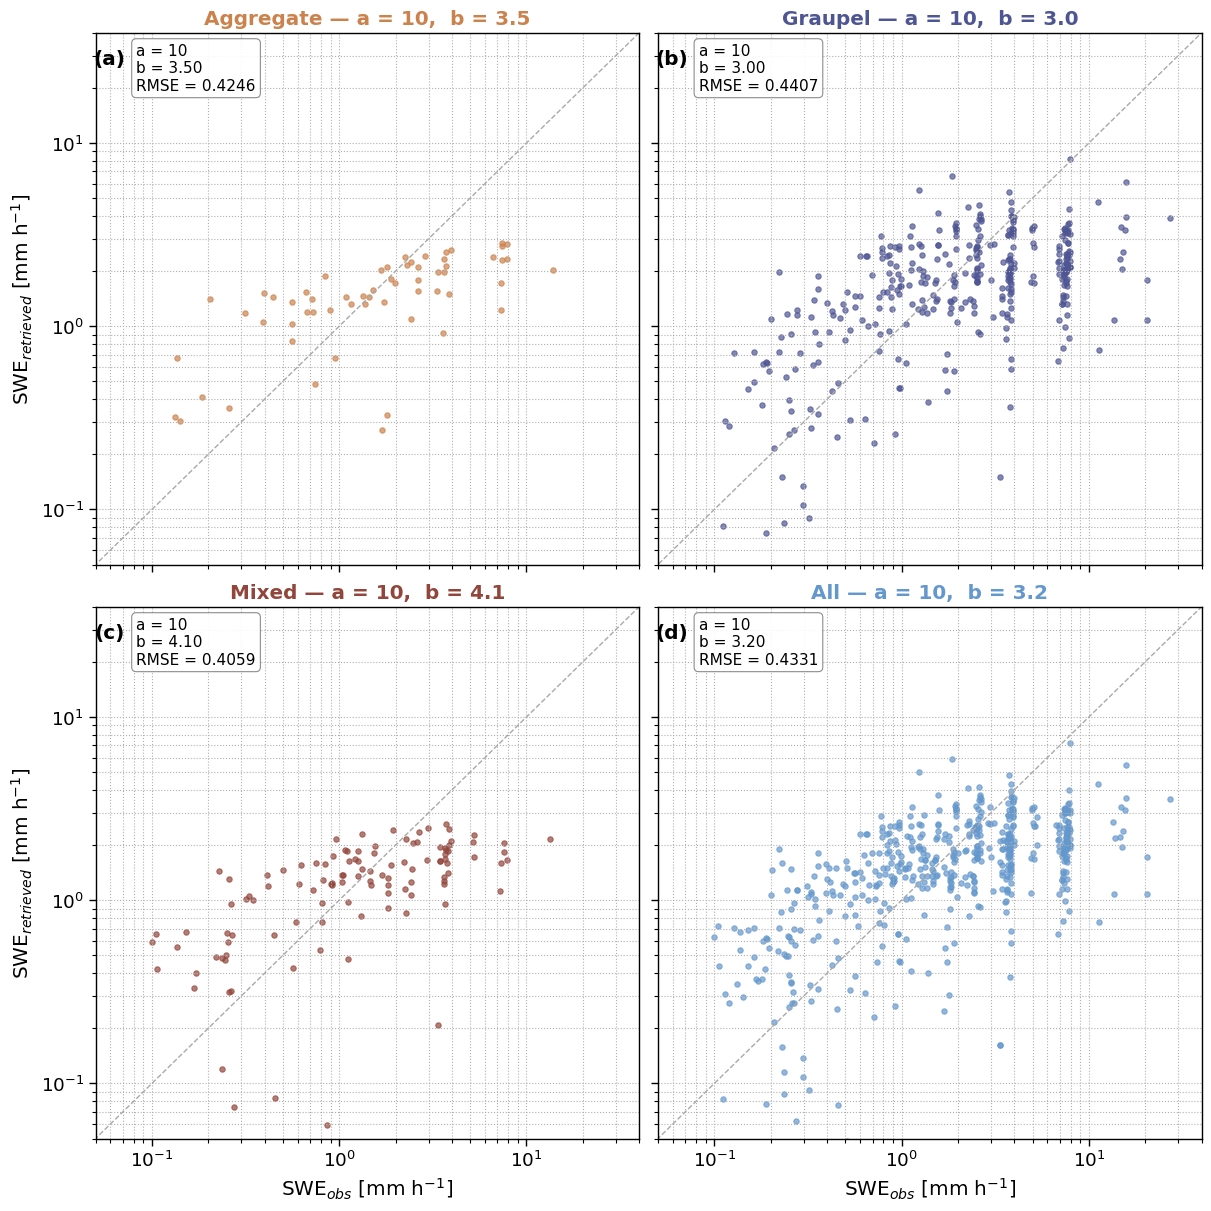

In [84]:
plt_scatter_SWEobs_SWEret_4x4(rmse_ab['snowflake_class'], df_rmse['snowflake_class'], sf_class_dict, ['aggregate', 'graupel', 'mixed', 'all'])

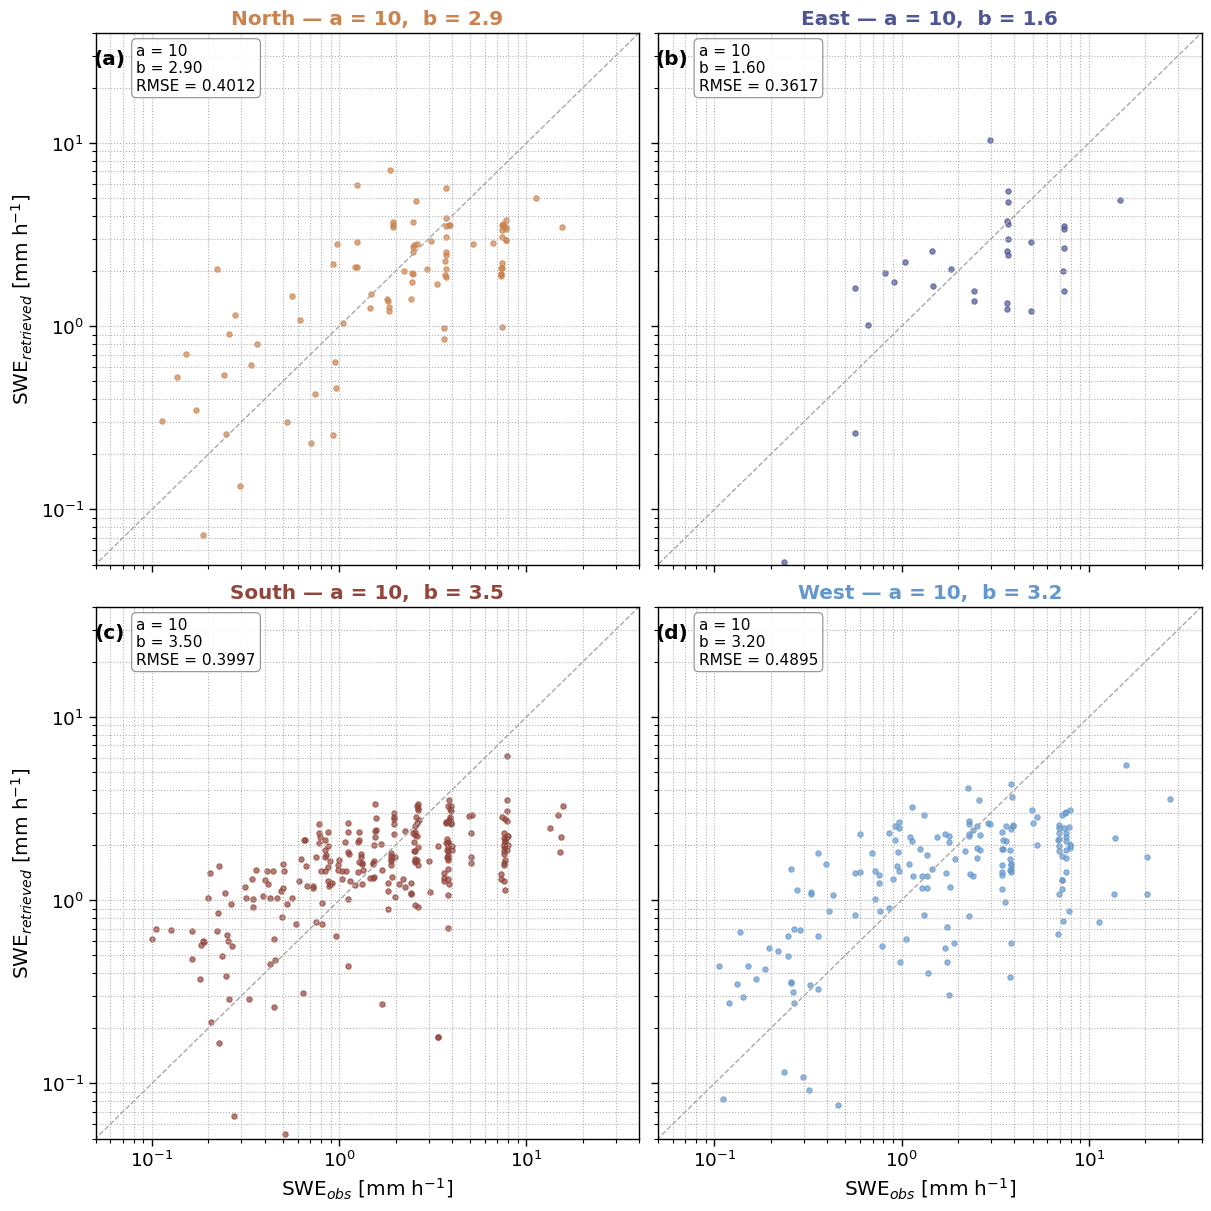

In [85]:
plt_scatter_SWEobs_SWEret_4x4(rmse_ab['wind_direction_sector'], df_rmse['wind_direction_sector'], wd_sector_dict, ['North', 'East', 'South', 'West'])

(0.0, 61.0)

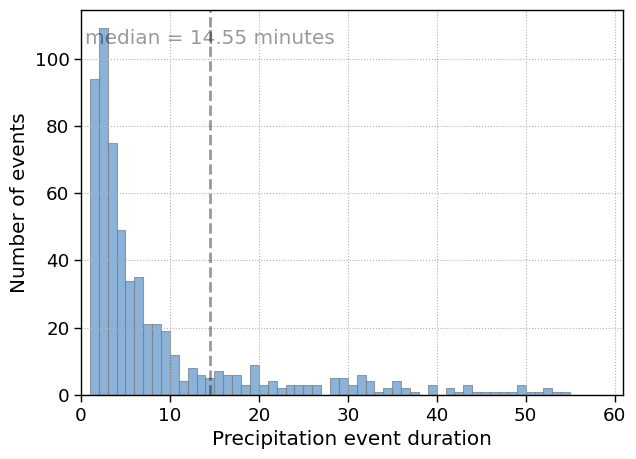

In [ ]:
event_duration = (sf_class_dict['all']['delta_h']*60) # minutes
fig, ax = plt.subplots(1,1, figsize=(7,5))
ax.hist(event_duration, bins=np.arange(0, 60,1), color=custom_colors['all'], edgecolor="grey", alpha=0.75)

q = np.percentile(Ze_400_obs, [25, 50, 75])
iqr = q[2] - q[0]

ax.axvline(q[1], color="k", ls="--", alpha=0.4)
ax.text(q[1], ax.get_ylim()[1]*0.9, f"median = {q[1].round(2)} minutes", color="k", alpha=0.4, horizontalalignment='center', verticalalignment='bottom')
ax.grid(True, ls=":")
ax.set_xlabel("Precipitation event duration")
ax.set_ylabel("Number of events")
ax.set_xlim([0, 61])

In [70]:
from imports import BoundaryNorm

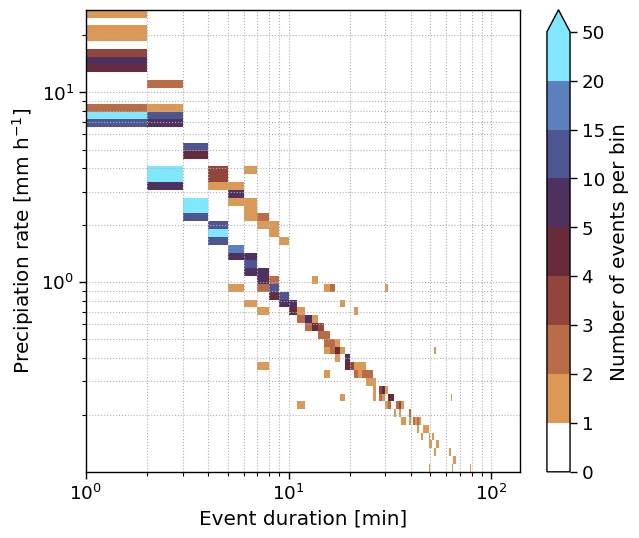

In [111]:
precip = sf_class_dict['all']['rate_mm_h'] # mm/h


# remove NaNs
mask = np.isfinite(event_duration) & np.isfinite(precip) & (event_duration >0) & (precip>0)
x = event_duration[mask]
y = precip[mask]

x_bins = np.arange(x.min(), x.max())
y_bins = np.logspace(np.log10(y.min()), np.log10(y.max()), 60)
H, xedges, yedges = np.histogram2d(x, y, bins=[x_bins, y_bins])

# --- Discrete levels for colorbar ---
levels = [0, 1, 2, 3, 4, 5, 10, 15, 20, 50]   # ← adjust to your data density
cmap = cm.managua
## extract all colors from the colormap
cmaplist = [cmap(i) for i in range(cmap.N)]
# force the first color entry to be white
cmaplist[0] = (255,255,255, 0.9)
# create the new map
cmap = LinearSegmentedColormap.from_list(
    'Custom cmap', cmaplist, len(levels))
norm = BoundaryNorm(levels, cmap.N, clip=True)

fig, ax = plt.subplots(figsize=(7,6))
# h = ax.hist2d(x, y, bins=[50,50], cmap=custom_cmap)
pcm = ax.pcolormesh(xedges, yedges, H.T, cmap=cmap, norm=norm, shading='auto', )

cbar = plt.colorbar(pcm, ax=ax, extend='max')
cbar.set_label("Number of events per bin")

ax.set_xlabel("Event duration [min]")
ax.set_ylabel("Precipiation rate [mm h$^{-1}$]")
ax.set_yscale('log')
ax.set_xscale('log')
ax.grid(ls=":", which='both')
